# Mulitlayer Perceptron Implementation Notebook

This notebook contains the MLP model building and testing on the three dataset. 

# Import Libraries

In [40]:
import pandas as pd
import numpy as np
import re
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, ParameterGrid, train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.base import clone
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from skorch import NeuralNetClassifier
from sklearn.metrics import average_precision_score, ndcg_score, precision_score
from sklearn.metrics import roc_curve, auc, ndcg_score

# Load datasets

In [2]:
# Load feature datasets
X_train_roberta = pd.read_csv('X_train_roberta.csv')
X_test_roberta = pd.read_csv('X_test_roberta.csv')

X_train_distilroberta = pd.read_csv('X_train_distilroberta.csv')
X_test_distilroberta = pd.read_csv('X_test_distilroberta.csv')

X_train_distilroberta_mitch = pd.read_csv('X_train_distilroberta_mitch.csv')
X_test_distilroberta_mitch = pd.read_csv('X_test_distilroberta_mitch.csv')

# Load target datasets
y_train = pd.read_csv('y_train.csv')
y_test = pd.read_csv('y_test.csv')

target_group_train = pd.read_csv('target_train.csv')
target_group_test = pd.read_csv('target_test.csv')

# Preprocess Data

## Feature Engineering
The release_year column was grouped into generation because realse year had 56 unique values which can cause high dimensionality.

## Categorical feature encoding
In the cell below, the predictor categorical variable was encoded to numerical value [0,1] using one-hot encoding. One-hot encoding is used so that the model will not misinterpret the encoded value as a hierarchy or order. The target variable was encoded using label encoder because it is binary.

## Numerical feature Normalisation

The numerical value was normalised because the box plot in Exploratory Data Analysis Notebook showed that the values had diverse range.

In [3]:
def extract_year_from_date(date_str):
    """
    Extract the year from a date string using regex to find the first 4-digit sequence.
    """
    match = re.search(r'\d{4}', date_str)
    if match:
        return int(match.group(0))  # Return the first 4-digit match as an integer
    return None  # Return None if no match is found

def map_year_to_generation(year):
    """
    Map a given year to a generation name.
    """
    if year >= 2013:
        return 'Generation Alpha'
    elif year >= 1997:
        return 'Generation Z'
    elif year >= 1981:
        return 'Millennials'
    elif year >= 1965:
        return 'Generation X'
    elif year >= 1946:
        return 'Baby Boomers'
    elif year >= 1928:
        return 'Silent Generation'
    else:
        return 'Unknown'

def preprocess_data(df, mood_column='final_mood_roberta', text_column = 'text_roberta'):
    # Extract the year using regex
    df['year'] = df['release_date'].apply(extract_year_from_date)
    
    # Map the year to generation names
    df['generation'] = df['year'].apply(map_year_to_generation)
    
    # Drop unnecessary columns including 'year'
    df = df.drop(columns=['artist_name', text_column, 'release_date', 'first_genre', 'year'])
    
    # Standardize numerical features
    numerical_features = [
        'liveness', 'loudness', 'popularity', 'acousticness',
        'speechiness', 'tempo', 'valence', 'danceability', 'energy'
    ]
    
    scaler = MinMaxScaler()
    df[numerical_features] = scaler.fit_transform(df[numerical_features])
    
    # One-hot encode categorical features including the mood column
    categorical_features = [mood_column, 'target_group', 'generation']
    df = pd.get_dummies(df, columns=categorical_features, drop_first=True, dtype=int)
    
    return df

In [4]:
X_train_roberta= preprocess_data(X_train_roberta, mood_column = 'final_mood_roberta', text_column = 'text_roberta')
X_test_roberta= preprocess_data(X_test_roberta, mood_column = 'final_mood_roberta', text_column = 'text_roberta')

In [5]:
X_train_distilroberta= preprocess_data(X_train_distilroberta, mood_column = 'final_mood_jhart', text_column = 'text_distilroberta')
X_test_distilroberta= preprocess_data(X_test_distilroberta, mood_column = 'final_mood_jhart', text_column = 'text_distilroberta')

In [6]:
X_train_distilroberta_mitch= preprocess_data(X_train_distilroberta_mitch, mood_column = 'final_mood_mitch', text_column = 'text_distilroberta_mitch')
X_test_distilroberta_mitch= preprocess_data(X_test_distilroberta_mitch, mood_column = 'final_mood_mitch', text_column = 'text_distilroberta_mitch')

## Split Training Data to get 20% validation data

In [7]:
from sklearn.model_selection import train_test_split

# Generate indices for the train-validation split
train_indices, val_indices = train_test_split(
    range(len(X_train_roberta)), test_size=0.2, random_state=42
)

# Use these indices to index each dataset
X_train_roberta_train = X_train_roberta.iloc[train_indices]
X_val_roberta = X_train_roberta.iloc[val_indices]

X_train_distilroberta_train = X_train_distilroberta.iloc[train_indices]
X_val_distilroberta = X_train_distilroberta.iloc[val_indices]

X_train_distilroberta_mitch_train = X_train_distilroberta_mitch.iloc[train_indices]
X_val_distilroberta_mitch = X_train_distilroberta_mitch.iloc[val_indices]

y_train_train = y_train.iloc[train_indices]
y_val = y_train.iloc[val_indices]

target_group_train_split = target_group_train.iloc[train_indices]
target_group_val_split = target_group_train.iloc[val_indices]

# Now you have:
# - Training sets: X_train_roberta_train, X_train_distilroberta_train, X_train_distilroberta_mitch_train, y_train_train
# - Validation sets: X_val_roberta, X_val_distilroberta, X_val_distilroberta_mitch, y_val


## Make the dataset tensors

In [8]:
X_train_roberta_train_tensor = torch.from_numpy(X_train_roberta_train.to_numpy()).type(torch.FloatTensor)
X_val_roberta_tensor = torch.from_numpy(X_val_roberta.to_numpy()).type(torch.FloatTensor)

X_train_distilroberta_train_tensor = torch.from_numpy(X_train_distilroberta_train.to_numpy()).type(torch.FloatTensor)
X_val_distilroberta_tensor = torch.from_numpy(X_val_distilroberta.to_numpy()).type(torch.FloatTensor)

X_train_distilroberta_mitch_train_tensor = torch.from_numpy(X_train_distilroberta_mitch_train.to_numpy()).type(torch.FloatTensor)
X_val_distilroberta_mitch_tensor = torch.from_numpy(X_val_distilroberta_mitch.to_numpy()).type(torch.FloatTensor)


# Convert target labels to PyTorch tensor
y_train_train_np = y_train_train.to_numpy()
y_train_tensor = torch.from_numpy(y_train_train_np).long()

# Convert target labels to PyTorch tensor
y_val_np = y_val.to_numpy()
y_val_tensor = torch.from_numpy(y_val_np).long()

# Evaluation Metrics

In [9]:
import numpy as np

def calculate_precision_at_k(y_true, y_pred_proba, k=20):
  """Calculates precision@k for binary classification.

  Args:
    y_true: True labels.
    y_pred_proba: Predicted probabilities.
    k: Number of top predictions to consider.

  Returns:
    Precision@k value.
  """

  # Rank predictions by probability
  indices = np.argsort(y_pred_proba)[::-1]

  # Apply threshold and select top k
  y_pred = (y_pred_proba[indices] > 0.5).astype(int)
  y_pred_top_k = y_pred[:k]

  # Retrieve actual labels
  y_true_top_k = y_true[indices][:k]

  # Calculate numerator and denominator
  numerator = np.sum(y_pred_top_k * y_true_top_k)
  denominator = np.sum(y_pred_top_k)

  # Calculate precision@k
  if denominator > 0:
    precision_at_k = numerator / denominator
  else:
    precision_at_k = 0

  return precision_at_k

In [10]:
import numpy as np
from sklearn.metrics import average_precision_score

def average_precision_top_k(y_true, y_pred_proba, k=20):
  """Calculates average precision for the top k predictions.

  Args:
    y_true: True binary labels.
    y_score: Target scores.
    k: Number of top predictions to consider.

  Returns:
    Average precision value.
  """

  # Filter top k predictions
  indices = np.argsort(y_pred_proba)[::-1]
  y_true_top_k = y_true[indices][:k]
  y_score_top_k = y_pred_proba[indices][:k]

  # Calculate average precision
  ap = average_precision_score(y_true_top_k, y_score_top_k)

  return ap

In [11]:
def calculate_ndcg(y_true, y_pred_proba, k=20):
  """Calculates NDCG for ranking tasks.

  Args:
    y_true: True relevance scores.
    y_score: Predicted relevance scores.
    k: Number of top items to consider.

  Returns:
    NDCG value.
  """

  # Calculate NDCG
  ndcg = ndcg_score(y_true, y_pred_proba, k=k)

  return ndcg

In [12]:
def calculate_ndcg_at_k(true_labels, predicted_scores, k):
    """Calculates Normalized Discounted Cumulative Gain (NDCG) at k.

    Args:
        true_labels: A list or NumPy array of true labels.
        predicted_scores: A list or NumPy array of predicted scores.
        k: The number of top predictions to consider.

    Returns:
        The NDCG at k.
    """

    if len(true_labels) == 0:
        return 0

    # Ensure k does not exceed the number of predicted scores
    k = min(k, len(predicted_scores))

    def dcg(relevance, k):
        relevance = np.array(relevance)[:k]  # Take top k relevant items
        return np.sum((2 ** relevance - 1) / np.log2(np.arange(2, len(relevance) + 2)))

    # Sort indices by descending predicted scores
    indices = np.argsort(predicted_scores)[::-1][:k]

    # Get top k true labels and calculate DCG
    top_k_true_labels = true_labels[indices]
    dcg_k = dcg(top_k_true_labels, k)

    # Calculate Ideal Discounted Cumulative Gain (IDCG)
    ideal_labels = np.sort(true_labels)[::-1][:k]
    idcg_k = dcg(ideal_labels, k)

    # Calculate NDCG
    ndcg_k = dcg_k / idcg_k if idcg_k > 0 else 0

    return ndcg_k

In [204]:
def compute_and_display_confusion_matrix(y_true, y_pred_proba, group=None):
    """
    Compute and display the confusion matrix for a given target group.

    Parameters:
    - y_true: True labels for the test set or validation fold.
    - y_pred_proba: Predicted probability scores from the model.
    - group: The target group for labeling purposes.
    
    Returns:
    - None
    """
    y_pred = (y_pred_proba > 0.5).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    
    # Display confusion matrix as a heatmap
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', cbar=False, 
                xticklabels=['Predicted Negative', 'Predicted Positive'], 
                yticklabels=['Actual Negative', 'Actual Positive'])
    plt.title(f'Confusion Matrix for {group}' if group else 'Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [14]:
def calculate_precision_score(y_true, y_pred_proba):
    """Calculates precision score for binary classification.

    Args:
        y_true: True binary labels.
        y_pred_proba: Predicted probability scores.
        average: Method for averaging precision across classes.
        pos_label: Positive class label.

    Returns:
        Precision score.
    """

    y_pred = (y_pred_proba > 0.5).astype(int)
    precision = precision_score(y_true, y_pred)
    return precision

In [205]:
def plot_roc_curve(y_true, y_pred_proba, group=None):
    """Plots the ROC curve for binary classification for each target group.

    Args:
        y_true: True binary labels.
        y_pred_proba: Predicted probability scores.
        group: The target group for labeling purposes.
    """
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba, pos_label=1)
    roc_auc = auc(fpr, tpr)

    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve for {group}' if group else 'Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc="lower right")
    plt.show()

In [209]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, confusion_matrix, precision_score

# Function to evaluate model on validation data for each target group and return metrics in a DataFrame
def evaluate_model_by_group(X_val, y_val, target_group_val, model, k=20):
    """Evaluates the model on validation data, calculates various metrics for each target group, and returns a DataFrame."""
    
    # Get predicted probabilities for the positive class
    y_pred_proba = model.predict_proba(X_val)[:, 1]
    
    # Convert y_val (PyTorch tensor or DataFrame) to NumPy array 
    if hasattr(y_val, 'numpy'):  
        y_val = y_val.numpy()
    elif isinstance(y_val, pd.DataFrame):  
        y_val = y_val.values.ravel()  
    elif isinstance(y_val, pd.Series):  
        y_val = y_val.values  
    
    # Convert target_group_val (pandas DataFrame) to a flattened pandas Series
    target_group_val = target_group_val.iloc[:, 0]  # Convert DataFrame to Series if needed

    
    # Create a DataFrame with predicted probabilities, true labels, and target groups
    results_df = pd.DataFrame({
        'y_true': y_val,
        'y_pred_proba': y_pred_proba,
        'target_group': target_group_val
    })

    # Prepare a list to hold the metrics for each group
    metrics_list = []

    # Calculate precision@k and other metrics for each target group
    for group in results_df['target_group'].unique():
        group_df = results_df[results_df['target_group'] == group]
        
        # Calculate precision@k, average precision@k, ndcg@k, and other metrics
        precision_at_k = calculate_precision_at_k(group_df['y_true'].values, group_df['y_pred_proba'].values, k=k)
        average_precision_at_k = average_precision_top_k(group_df['y_true'].values, group_df['y_pred_proba'].values, k=k)
        ndcg_at_k = calculate_ndcg_at_k(group_df['y_true'].values, group_df['y_pred_proba'].values, k=k)
        precision_score_value = precision_score(group_df['y_true'].values, (group_df['y_pred_proba'].values > 0.5).astype(int),
                                               zero_division=0)

        # Plot ROC curve and confusion matrix for the group
        plot_roc_curve(group_df['y_true'].values, group_df['y_pred_proba'].values, group)
        compute_and_display_confusion_matrix(group_df['y_true'].values, group_df['y_pred_proba'].values, group)

        # Store the results in a dictionary
        metrics_dict = {
            'target_group': group,
            'precision_at_k': precision_at_k,
            'average_precision_at_k': average_precision_at_k,
            'ndcg_at_k': ndcg_at_k,
            'precision_score': precision_score_value
        }
        
        # Append the metrics for this group to the list
        metrics_list.append(metrics_dict)

    # Convert the list of metrics dictionaries to a DataFrame
    metrics_df = pd.DataFrame(metrics_list)
    
    return metrics_df, results_df


# Model Building

## Baseline Model Architecture
MLP class allows building customised feed-forward multilayer perceptron (MLP) models architecture. With this class, uthe number of hidden layers, as well as the number of neurons in the input, hidden, and output layers can be specified. Additionally, it allows for the external definition of activation functions and dropout sizes.

This class implements fully connected layers for the input, hidden, and output layers. If dropout is selected, it is applied only to the last hidden layer, following a recommendation by Géron (2019), before the data is passed to the output layer. A sigmoid activation function is applied to the output layer to produce class probabilities ranging between 0 and 1.

In [16]:
class MLP(nn.Module):
    def __init__(self, input_size, output_size, hidlayers, hidden_sizes, activation, dropout):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_sizes[0])
        self.fc2 = nn.ModuleList()
        for i in range(hidlayers - 1):
            self.fc2.append(nn.Linear(hidden_sizes[i], hidden_sizes[i+1]))
        self.fc3 = nn.Linear(hidden_sizes[-1], output_size)
        self.hidlayers = hidlayers
        self.dropout = nn.Dropout(dropout)
        self.act = activation
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        input_layer = self.act(self.fc1(x))  
        for layer in self.fc2:
            hidden_layer = self.act(layer(input_layer))  
            input_layer = hidden_layer
        hidden_layer = self.dropout(hidden_layer)
        output_layer = self.sigmoid(self.fc3(hidden_layer))  
        return output_layer

### Baseline Model with 2 hidden layers of 52, 25 neurons sizes, 0.001 learning rate

With skorch's NeuralNetClassifier, the baseline model was built. The MLP class was initialised here. The input size is the number of predictor for the datasets 

The baseline model is a 2 hidden layer MLP with an 52 neuron size in first hidden layer and 25 in the second hidden layer. 

It uses LeakyReLU, a simple variant of ReLU that does a direct mapping like ReLU but then maps small values less than 0 to solve dying neuron problem of ReLU and vanishing gradient problem of Sigmoid and tanh.

It uses cross entropy loss function to compute loss in the output layer and uses stochastic gradient descent for backpropagation and undate weights to minimise error 

In [139]:
def initialize_mlp(input_size):
    net = NeuralNetClassifier(
        module=MLP,
        module__input_size=input_size,
        module__hidlayers=2,  
        module__hidden_sizes=[52, 25],
        module__output_size=2,  
        module__activation=nn.LeakyReLU(),
        module__dropout=0,
        batch_size=128,
        max_epochs=700,
        criterion=nn.CrossEntropyLoss,  
        optimizer=torch.optim.SGD,
        optimizer__lr=0.001,
        train_split=dataset.ValidSplit(cv=5, stratified=True),
        callbacks=[
            callbacks.EpochScoring(scoring='accuracy', name='train_acc', on_train=True),
            callbacks.EarlyStopping(monitor='valid_loss',patience = 30, threshold = 0.01)
        ]
          
    )
    return net

In [140]:
def mlp_baseline_model(initialize_mlp, X_train_tensor, y_train_tensor):
    """
    Trains the Skorch model and extracts training metrics.

    Args:
        net: Skorch NeuralNetClassifier model to be trained.
        X_train: Training features (Tensor or Numpy array).
        y_train: Training labels (Tensor or Numpy array).

    Returns:
        A dictionary containing training and validation losses, accuracies, and the total training time.
    """
    # Train the model
    X_train_tensor = X_train_tensor.numpy()  # Convert tensor to numpy array
    y_train_tensor = y_train_tensor.numpy().ravel()
    
    net = initialize_mlp(input_size=X_train_tensor.shape[1])
    net.fit(X_train_tensor, y_train_tensor)

    # Extract metrics from the training history
    history = net.history

    val_losses = history[:, 'valid_loss']
    val_accuracy = history[:, 'valid_acc']
    train_loss = history[:, 'train_loss']
    train_acc = history[:, 'train_acc']
    train_time = history[:, 'dur']
    total_time = sum(train_time)

    return net, val_losses, val_accuracy, train_loss, total_time


## Roberta

### Train Roberta data on baseline model 

In [141]:
net, val_losses, val_accuracy, train_loss, total_time = mlp_baseline_model(initialize_mlp, X_train_roberta_train_tensor, y_train_tensor)

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4628        0.6940       0.4627        0.6940  0.1353
      2       0.4634        0.6939       0.4627        0.6940  0.1243
      3       0.4648        0.6939       0.4627        0.6940  0.1248
      4       0.4657        0.6938       0.4621        0.6939  0.1775
      5       0.4672        0.6938       0.4639        0.6939  0.1510
      6       0.4681        0.6938       0.4681        0.6938  0.1094
      7       0.4702        0.6937       0.4712        0.6938  0.1159
      8       0.4725        0.6937       0.4748        0.6938  0.1241
      9       0.4738        0.6936       0.4733        0.6937  0.1318
     10       0.4757        0.6936       0.4754        0.6937  0.1126
     11       0.4785        0.6936       0.4775        0.6936  0.1158
     12       0.4811        0.6935       0.4782        0.6936  0.1138
     13       0.4834

### Function: train_val
This function is used to plot the accuracy and loss of both train and validation set per epoch to check model's performance

In [142]:
def train_val(train_loss, val_losses, train_acc, val_accuracy, title):
    plt.plot(range(len(train_loss)), train_loss, label='Train Loss')
    plt.plot(range(len(val_losses)), val_losses, label='Validation Loss')
    plt.plot(range(len(train_acc)), train_acc, label='Train Accuracy')
    plt.plot(range(len(val_accuracy)), val_accuracy, label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Value')
    plt.title(title)
    plt.legend()
    plt.show()

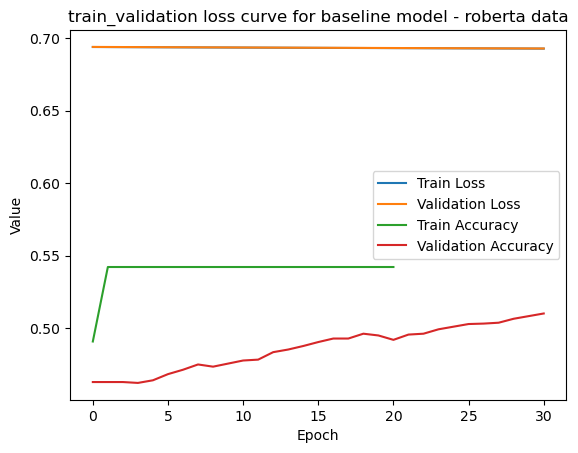

In [143]:
train_val(train_loss, val_losses, train_acc, val_accuracy, title='train_validation loss curve for baseline model - roberta data')

* Baseline model performed poorly on Roberta Data

### Roberta hyperparameter tuning - 2 hidden layers

Because of the limitations of skorch, I had to perform hyperparameter tuning for 1, 2, 3 hidden layers separately. This method is still effective and fair for evaluation because the other hyperparameters tuned in each were all the same

In [149]:
from skorch import NeuralNetClassifier, callbacks, dataset
net_model = NeuralNetClassifier(
    module=MLP,  
    module__input_size=X_train_roberta_train_tensor.shape[1],  
    module__hidlayers=2,  # Two hidden layers
    module__hidden_sizes=[52, 25], 
    module__output_size=2,  
    module__activation=nn.LeakyReLU(),  # LeakyReLU activation function
    batch_size=128,
    max_epochs=60,
    criterion=nn.CrossEntropyLoss,  # Cross entropy for binary classification
    optimizer=torch.optim.SGD,  # Stochastic Gradient Descent optimizer
    optimizer__lr=0.01,  # Learning rate
    module__dropout=0.2,  # Dropout rate set to 0
    optimizer__momentum=0.9,  # Momentum for the optimizer
    train_split=dataset.ValidSplit(cv=5, stratified=True),
    callbacks=[
        callbacks.EpochScoring(scoring='accuracy', name='train_acc', on_train=True),
        callbacks.EarlyStopping(monitor='valid_loss',patience = 20, threshold = 0.01)
    ]
)

param_grid2 = {
    'module__hidden_sizes': [[52, 25], [60,30], [40,20], [100, 50]],  
    'optimizer__lr': [0.001, 0.01, 0.1, 1],  
    'optimizer__momentum': [0, 0.5, 0.9],
    'module__dropout': [0.0, 0.2, 0.5]
}

grid = GridSearchCV(estimator=net_model, param_grid=param_grid2, n_jobs=-1, cv=5)

In [150]:
grid_result_roberta = grid.fit(X_train_roberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())

There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/hugg

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4580        0.6959       0.4577        0.6957  0.1022
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5420        0.6904       0.5423        0.6903  0.1095
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5420        0.6916       0.5423        0.6916  0.1178
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5420        0.6923       0.5419        0.6924  0.1243
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4795

In [157]:
# Update the parameters of the neural network with the best found parameters
net_model.set_params(**best_params)

# Fit the model with the best parameters using your training data
net_model.fit(X_train_roberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())

train_loss = net_model.history[:, 'train_loss']
train_acc = net_model.history[:, 'train_acc']
val_loss = net_model.history[:, 'valid_loss']
val_acc = net_model.history[:, 'valid_acc']

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5421        0.6896       0.5422        0.6882  0.3262
      2       0.5485        0.6851       0.5698        0.6817  0.2873
      3       0.5897        0.6737       0.6250        0.6610  0.2229
      4       0.6311        0.6493       0.6520        0.6346  0.2330
      5       0.6492        0.6370       0.6626        0.6273  0.2328
      6       0.6566        0.6283       0.6641        0.6209  0.2219
      7       0.6651        0.6229       0.6696        0.6177  0.2447
      8       0.6744        0.6168       0.6681        0.6168  0.2376
      9       0.6789        0.6123       0.6778        0.6144  0.2565
     10       0.6847        0.6086       0.6732        0.6132  0.2450
     11       0.6835        0.6070       0.6717        0.6133  0.2307
     12       0.6891        0.6050       0.6705        0.6148  0.2378
     13       0.6964

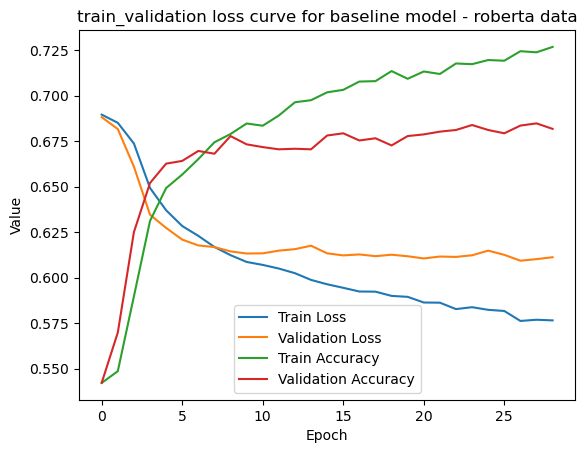

In [159]:
train_val(train_loss, val_loss, train_acc, val_acc, title='train_validation loss curve for baseline model - roberta data')

* The hypeparameter tuning of two hidden layer neurons, learning rate, drop out and momentum was better than the baseline model. But it overfitted to the training data

### Roberta - hyperparameter tuning of 3 hidden layers

In [311]:
net_3 = NeuralNetClassifier(
    module=MLP,
    module__input_size=X_train_roberta_train_tensor.shape[1],
    module__hidlayers=3,  
    module__hidden_sizes=[52, 25, 10],
    module__output_size=2,
    module__activation=nn.LeakyReLU(),
    batch_size=128,
    max_epochs=60,
    criterion=torch.nn.CrossEntropyLoss(),
    optimizer=torch.optim.SGD,
    optimizer__lr=0.001,
    module__dropout=0.0,
    optimizer__momentum=0.9,
    callbacks=[
        callbacks.EpochScoring(scoring='accuracy', name='train_acc', on_train=True),
        callbacks.EarlyStopping(monitor='valid_loss',patience = 30, threshold = 0.01)
    ]
)


param_grid3 = {
    'module__hidden_sizes': [[52, 25, 10],[60,30,20], [65,50,30], [40,20,10], [100,70,40]],
    'optimizer__lr':[0.001, 0.01, 0.1, 1],
    'optimizer__momentum':[0, 0.5, 0.9],
    'module__dropout': [0.0, 0.2, 0.5]
    
}

grid_3 = GridSearchCV(estimator=net_3, param_grid=param_grid3, n_jobs=-1, cv=5)

In [312]:
grid_result_roberta = grid_3.fit(X_train_roberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())

There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/hugg

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5420        0.6913       0.5423        0.6912  0.2155
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4580        0.6945       0.4577        0.6945  0.2060
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4581        0.6939       0.4581        0.6939  0.2246
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5420        0.6909       0.5423        0.6909  0.2073
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5421

In [166]:
grid_result_roberta.best_params_ #best parameters

{'module__dropout': 0.0,
 'module__hidden_sizes': [52, 25, 10],
 'optimizer__lr': 0.1,
 'optimizer__momentum': 0.9}

In [313]:
# Update the parameters of the neural network with the best found parameters
net_3.set_params(**grid_result_roberta.best_params_)

# Fit the model with the best parameters using training data
net_3.fit(X_train_roberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())

train_loss = net_model.history[:, 'train_loss']
train_acc = net_model.history[:, 'train_acc']
val_loss = net_model.history[:, 'valid_loss']
val_acc = net_model.history[:, 'valid_acc']

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5429        0.6895       0.5422        0.6876  0.1812
      2       0.5570        0.6824       0.5789        0.6744  0.3461
      3       0.6075        0.6619       0.6317        0.6472  0.2441
      4       0.6390        0.6434       0.6344        0.6463  0.3099
      5       0.6492        0.6374       0.6520        0.6291  0.2983
      6       0.6575        0.6282       0.6532        0.6377  0.2472
      7       0.6630        0.6271       0.6581        0.6244  0.2632
      8       0.6671        0.6211       0.6602        0.6213  0.2434
      9       0.6706        0.6179       0.6687        0.6254  0.2622
     10       0.6748        0.6163       0.6717        0.6220  0.2364
     11       0.6782        0.6144       0.6535        0.6262  0.2419
     12       0.6787        0.6110       0.6778        0.6142  0.2320
     13       0.6827

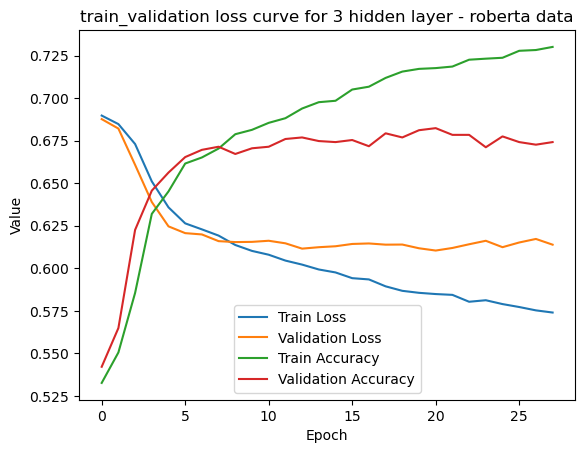

Stopping since valid_loss has not improved in the last 30 epochs.
Stopping since valid_loss has not improved in the last 30 epochs.
Stopping since valid_loss has not improved in the last 30 epochs.
Stopping since valid_loss has not improved in the last 30 epochs.
Stopping since valid_loss has not improved in the last 30 epochs.
Stopping since valid_loss has not improved in the last 30 epochs.
Stopping since valid_loss has not improved in the last 30 epochs.


In [314]:
train_val(train_loss, val_loss, train_acc, val_acc, title='train_validation loss curve for 3 hidden layer - roberta data')

* Still Overfitted

### Roberta - 1 hidden layer

In [192]:
# Define the MLP module with 1 hidden layer
class MLP1(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, activation, dropout):
        super(MLP1, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)  # First and only hidden layer
        self.activation = activation
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_size, output_size)  # Output layer

    def forward(self, x):
        x = self.activation(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Initialize the NeuralNetClassifier with 1 hidden layer
net_1_hidden_layer = NeuralNetClassifier(
    module=MLP1,
    module__input_size=X_train_roberta_train_tensor.shape[1],  # Adjust according to your feature size
    module__hidden_size=50,  # Number of neurons in the hidden layer (try 10, 20, 50, etc.)
    module__output_size=2,  # Assuming binary classification
    module__activation=nn.LeakyReLU(),  # Activation function
    module__dropout=0.5,  # Dropout for regularization (adjust as needed)
    max_epochs=50,
    batch_size=128,
    criterion=torch.nn.CrossEntropyLoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.01,
    train_split=dataset.ValidSplit(cv=5, stratified=True),  # Or specify a validation split
    optimizer__momentum=0.9,
    callbacks=[
        callbacks.EpochScoring(scoring='accuracy', name='train_acc', on_train=True),
        callbacks.EarlyStopping(monitor='valid_loss',patience = 30, threshold = 0.01)
    ]
)

# Fit the model
net_1_hidden_layer.fit(X_train_roberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())


  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5441        0.6883       0.5510        0.6858  0.1738
      2       0.5639        0.6823       0.5619        0.6820  0.1622
      3       0.5673        0.6781       0.5692        0.6792  0.1582
      4       0.5737        0.6763       0.5880        0.6751  0.1748
      5       0.5901        0.6701       0.5977        0.6700  0.1666
      6       0.5944        0.6672       0.6089        0.6641  0.1703
      7       0.6104        0.6595       0.6204        0.6570  0.1881
      8       0.6203        0.6528       0.6417        0.6489  0.1766
      9       0.6251        0.6477       0.6447        0.6437  0.1701
     10       0.6312        0.6431       0.6490        0.6371  0.1459
     11       0.6390        0.6382       0.6550        0.6331  0.1508
     12       0.6458        0.6313       0.6556        0.6296  0.1508
     13       0.6443

<class 'skorch.classifier.NeuralNetClassifier'>[initialized](
  module_=MLP1(
    (fc1): Linear(in_features=85, out_features=50, bias=True)
    (activation): LeakyReLU(negative_slope=0.01)
    (dropout): Dropout(p=0.5, inplace=False)
    (fc2): Linear(in_features=50, out_features=2, bias=True)
  ),
)

In [177]:
train_loss = net_1_hidden_layer.history[:, 'train_loss']
train_acc = net_1_hidden_layer.history[:, 'train_acc']
val_loss = net_1_hidden_layer.history[:, 'valid_loss']
val_acc = net_1_hidden_layer.history[:, 'valid_acc']

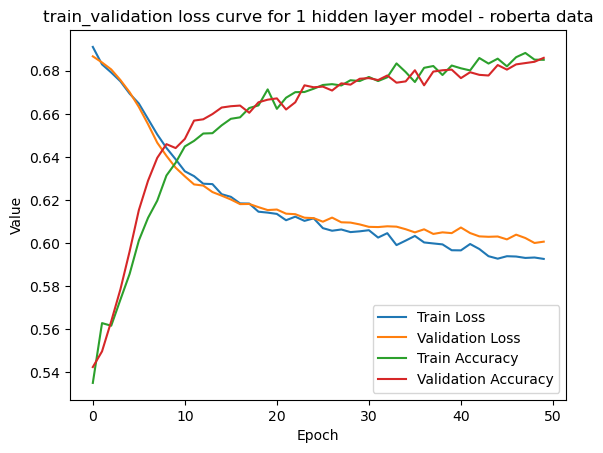

In [178]:
train_val(train_loss, val_loss, train_acc, val_acc, title='train_validation loss curve for 1 hidden layer model - roberta data')

* With this simpler mode architecture, overfitting reduced compared to the other

#### Roberta - hyperparameter tuning of 1 hidden layer

In [183]:
param_grid1 = {
    'module__hidden_size': [52,60,40,25],  # Example hidden layer sizes
    'optimizer__lr': [0.001, 0.01, 0.1, 1],  # Example learning rates
    'optimizer__momentum': [0, 0.5, 0.9],
    'module__dropout': [0.0, 0.2, 0.5]# Example momentum values
}

grid1 = GridSearchCV(estimator=net_1_hidden_layer, param_grid=param_grid1, n_jobs=-1, cv=5)

In [184]:
grid_result_roberta1 = grid1.fit(X_train_roberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())

There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/hugg

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5371        0.6944       0.5449        0.6935  0.1448
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4708        0.6974       0.4774        0.6963  0.1656
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4858        0.6966       0.4930        0.6946  0.1559
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5260        0.6916       0.5301        0.6909  0.1706
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5421

In [185]:
grid_result_roberta1.best_params_

{'module__dropout': 0.5,
 'module__hidden_size': 60,
 'optimizer__lr': 0.1,
 'optimizer__momentum': 0.9}

In [187]:
# Update the parameters of the neural network with the best found parameters
net_param = net_1_hidden_layer.set_params(**grid_result_roberta1.best_params_)

# Fit the model with the best parameters using training data
net_param.fit(X_train_roberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())

train_loss = net_model.history[:, 'train_loss']
train_acc = net_model.history[:, 'train_acc']
val_loss = net_model.history[:, 'valid_loss']
val_acc = net_model.history[:, 'valid_acc']

Re-initializing module because the following parameters were re-set: module__dropout, module__hidden_size.
Re-initializing criterion.
Re-initializing optimizer.
Re-initializing module because the following parameters were re-set: activation, dropout, hidden_size, input_size, output_size.
Re-initializing criterion.
Re-initializing optimizer.
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5400        0.6897       0.5464        0.6857  0.1377
      2       0.5594        0.6831       0.5540        0.6826  0.1731
      3       0.5621        0.6805       0.5622        0.6794  0.1734
      4       0.5720        0.6752       0.5786        0.6755  0.1122
      5       0.5815        0.6739       0.5953        0.6707  0.1567
      6       0.5973        0.6667       0.6068        0.6641  0.1717
      7       0.6048        0.6598       0.6229        0.6563  0.1649
      8       0.6127       

### Evaluate train, val and test data with the best model with 1 hidden layer

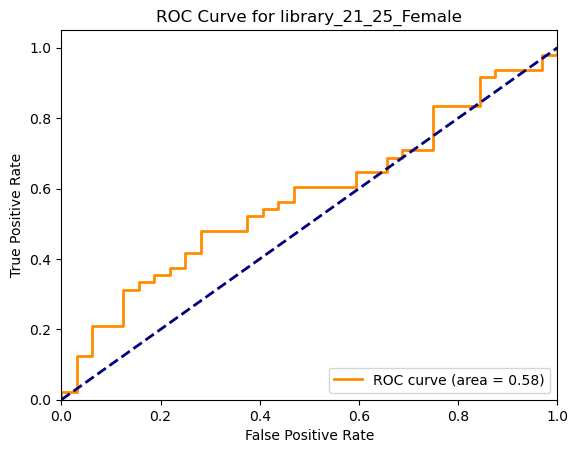

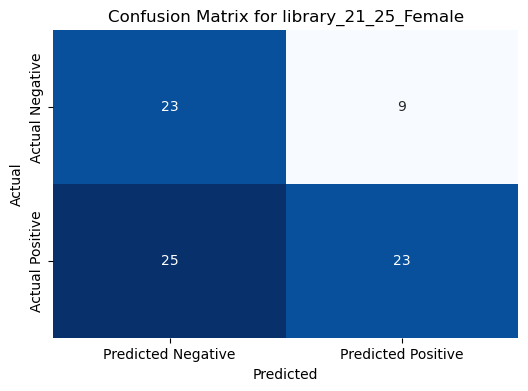

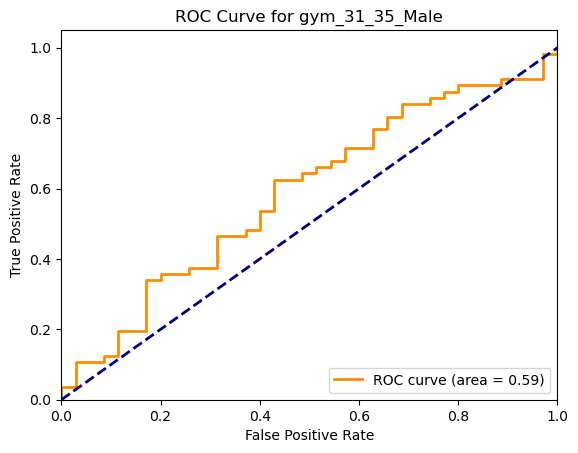

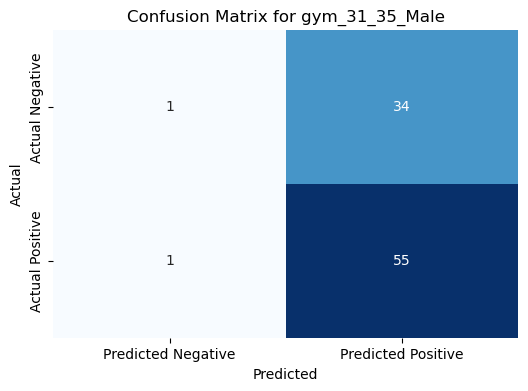

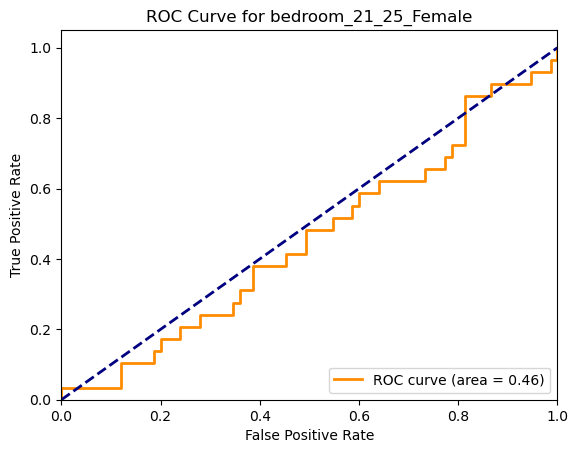

...

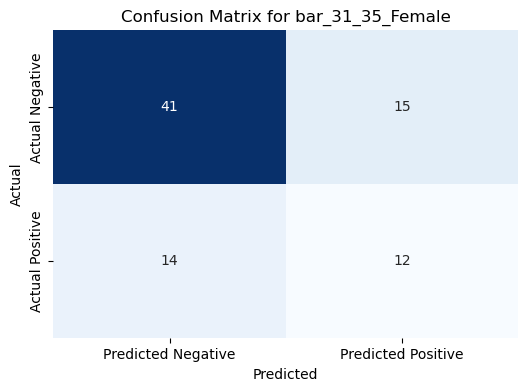

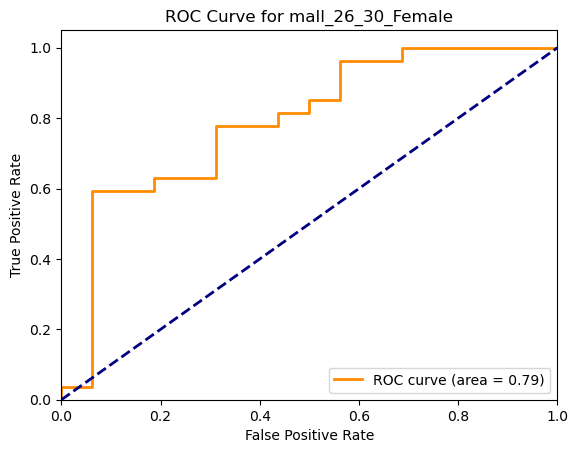

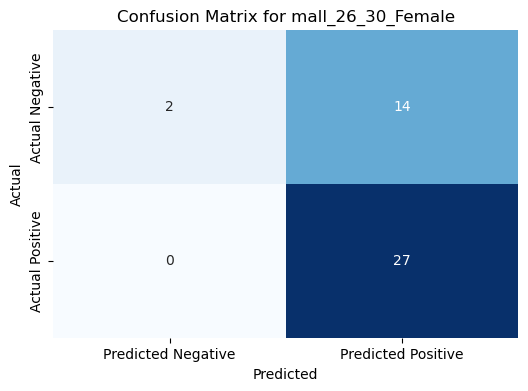

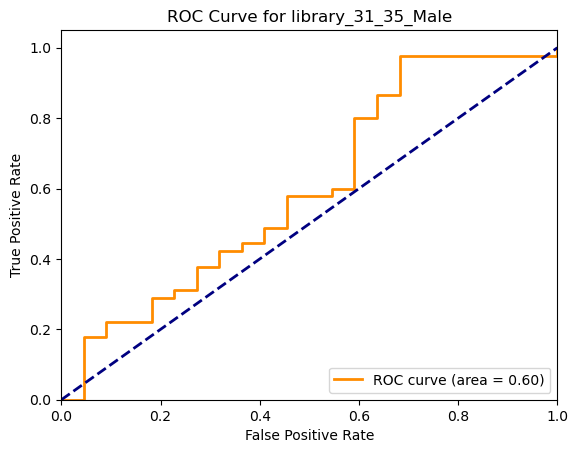

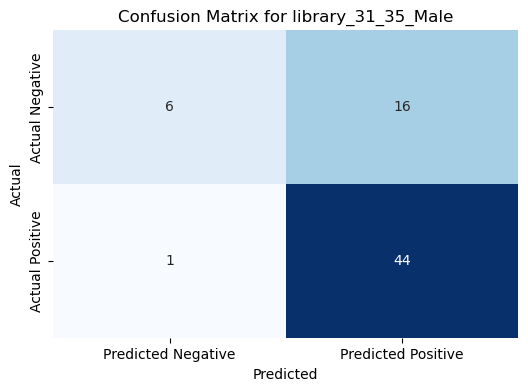

(               target_group  precision_at_k  average_precision_at_k  \
 0      library_21_25_Female        0.750000                0.796782   
 1            gym_31_35_Male        0.700000                0.771282   
 2      bedroom_21_25_Female        0.000000                0.380808   
 3       office_21_25_Female        0.750000                0.892278   
 4            gym_21_25_Male        0.000000                0.639927   
 5            gym_26_30_Male        0.600000                0.601508   
 6       trainbus_31_35_Male        1.000000                1.000000   
 7       office_26_30_Female        0.571429                0.757807   
 8      bedroom_26_30_Female        0.700000                0.649709   
 9        bedroom_26_30_Male        0.950000                0.930821   
 10    trainbus_26_30_Female        0.900000                0.890153   
 11  restaurant_21_25_Female        0.650000                0.800685   
 12      office_31_35_Female        0.526316                0.93

In [210]:
# val data
metrics_roberta, results_roberta = evaluate_model_by_group(X_val_roberta_tensor, y_val, target_group_val_split, net_1_hidden_layer, k=20)

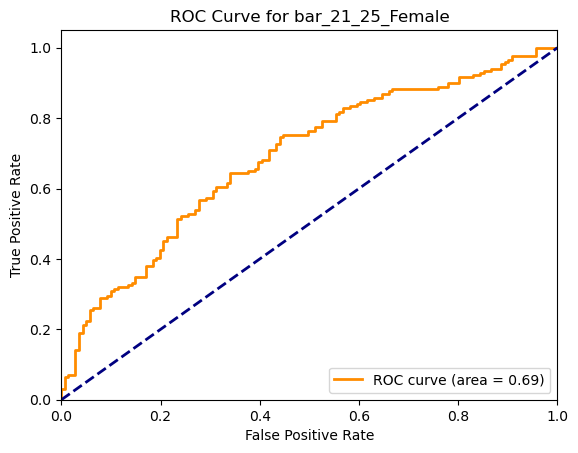

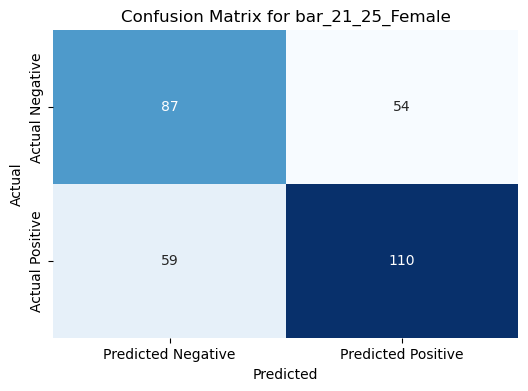

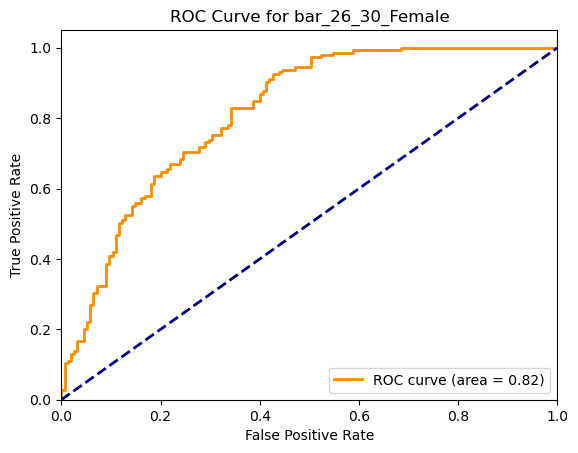

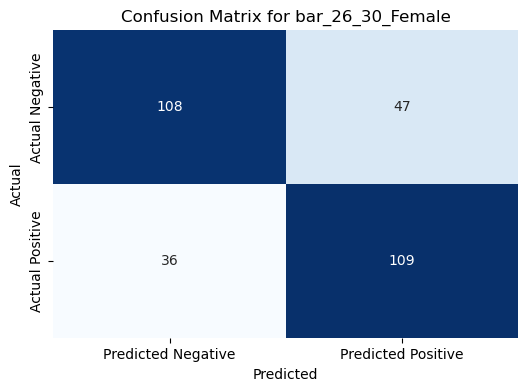

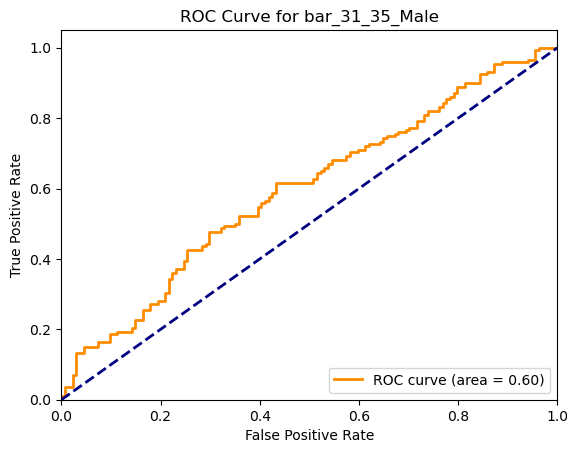

...

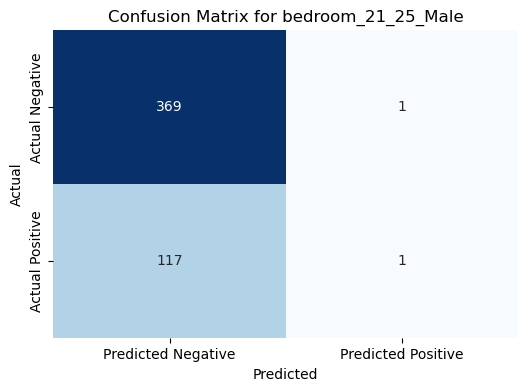

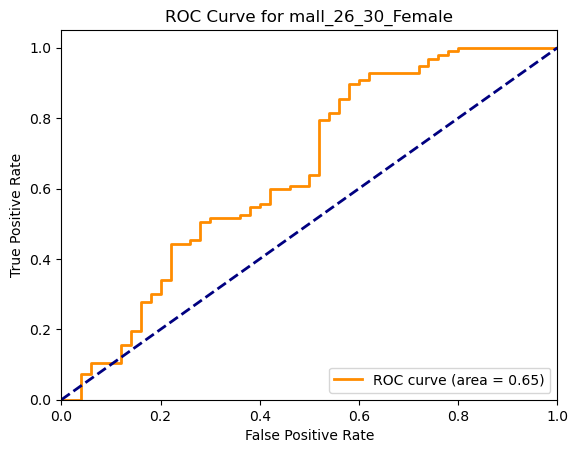

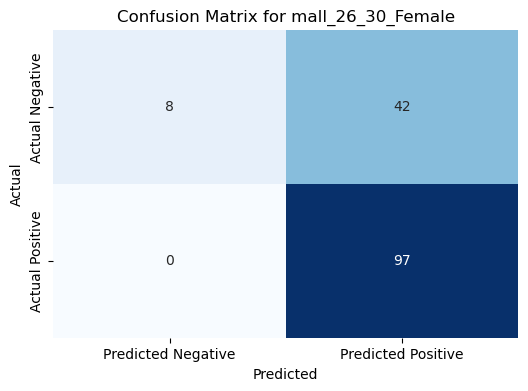

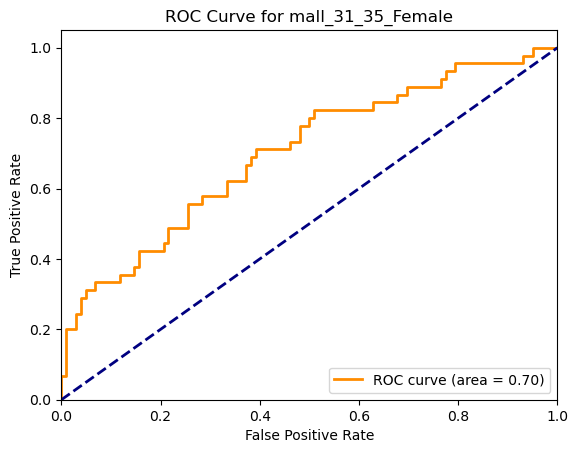

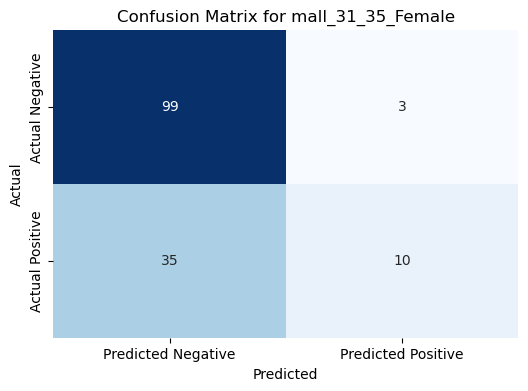

In [212]:
train data
metrics_roberta_t, results_roberta_t = evaluate_model_by_group(X_train_roberta_train_tensor, y_train_train, target_group_train_split, net_1_hidden_layer, k=20)

In [ ]:
# Test data

In [214]:
X_test_roberta_tensor = torch.from_numpy(X_test_roberta.to_numpy()).type(torch.FloatTensor)
y_test_np = y_test.to_numpy()
y_test_tensor = torch.from_numpy(y_val_np).long()

metrics_roberta_test, results_roberta_test = evaluate_model_by_group(X_test_roberta_tensor, y_test, target_group_test, net_1_hidden_layer, k=20)


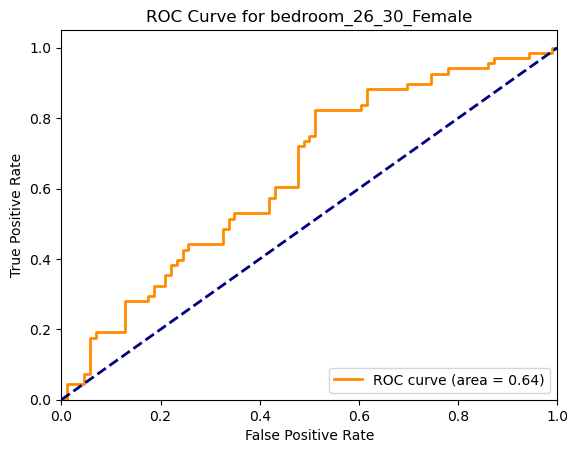

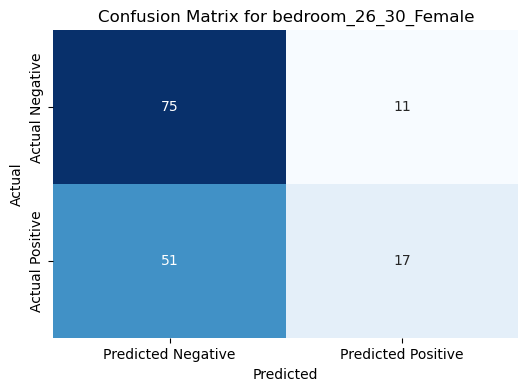

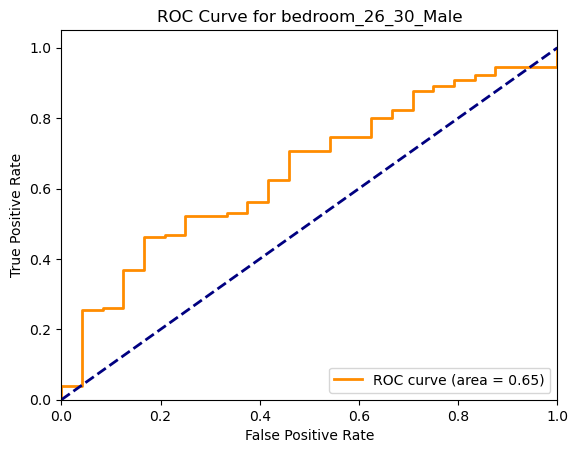

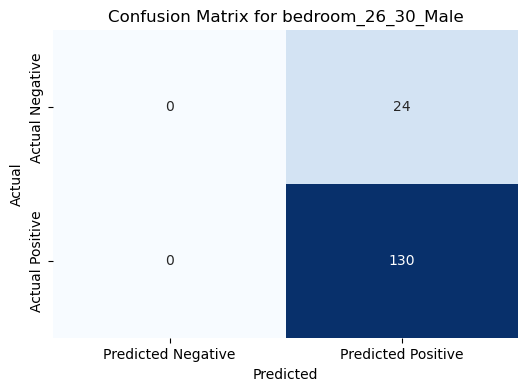

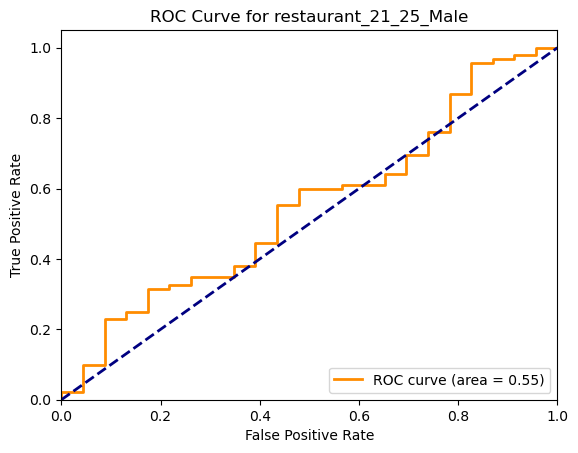

...

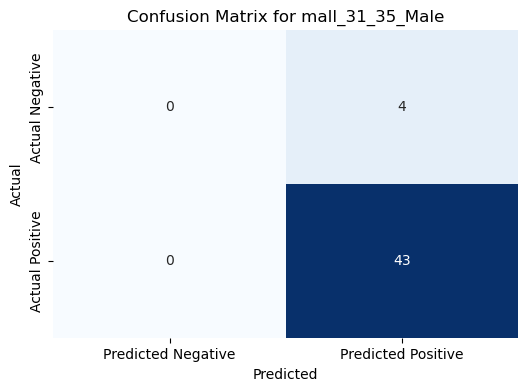

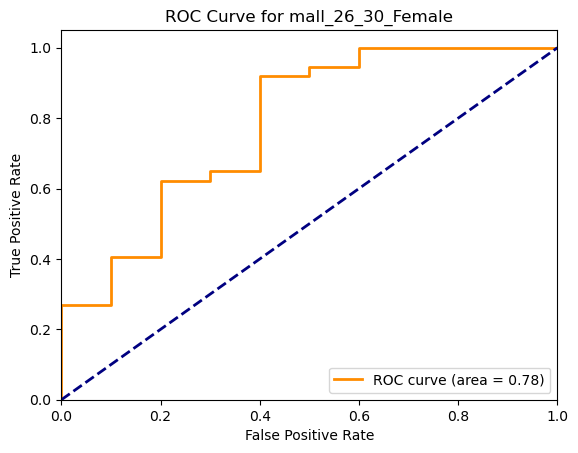

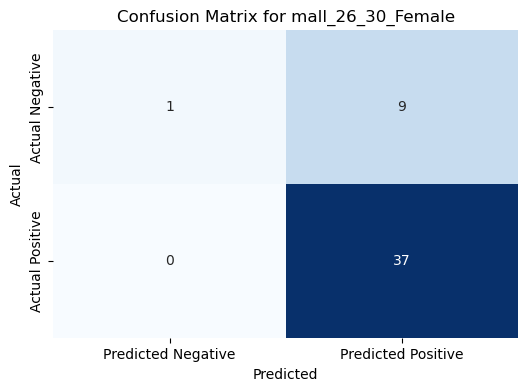

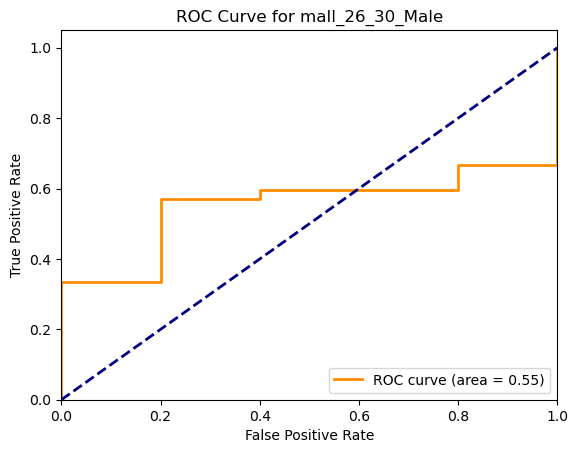

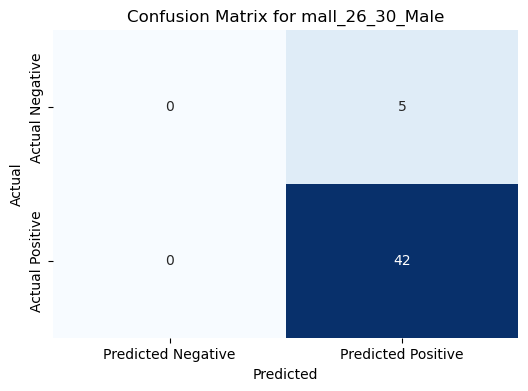

In [215]:
metrics_roberta_test, results_roberta_test = evaluate_model_by_group(X_test_roberta_tensor, y_test, target_group_test, net_1_hidden_layer, k=20)


In [316]:
metrics_roberta_test.to_csv('metrics_roberta_test_mlp.csv', index=False)

## DistilRoberta

### Apply baseline model to Distilroberta data

In [219]:
net, val_losses, val_accuracy, train_loss, total_time = mlp_baseline_model(initialize_mlp,
                                                                           X_train_distilroberta_train_tensor,
                                                                           y_train_tensor)


  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4579        0.6945       0.4578        0.6946  0.1984
      2       0.4579        0.6945       0.4578        0.6946  0.1504
      3       0.4579        0.6944       0.4578        0.6945  0.1200
      4       0.4579        0.6944       0.4578        0.6945  0.1196
      5       0.4579        0.6943       0.4578        0.6944  0.1117
      6       0.4579        0.6943       0.4578        0.6944  0.1645
      7       0.4579        0.6942       0.4578        0.6944  0.1546
      8       0.4578        0.6942       0.4578        0.6943  0.1122
      9       0.4578        0.6942       0.4578        0.6943  0.1199
     10       0.4578        0.6941       0.4578        0.6943  0.1090
     11       0.4577        0.6941       0.4578        0.6942  0.1096
     12       0.4575        0.6941       0.4581        0.6942  0.1337
     13       0.4576

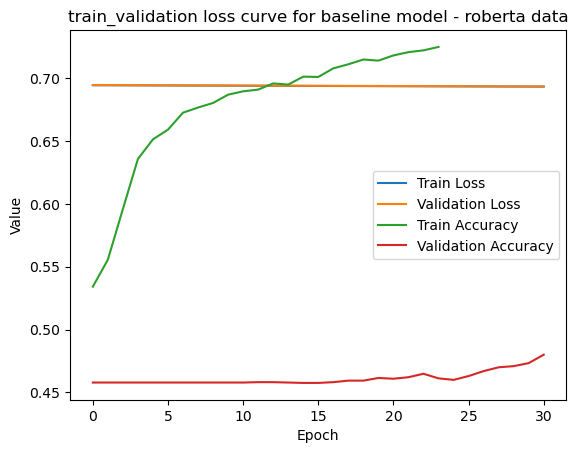

In [220]:
train_val(train_loss, val_losses, train_acc, val_accuracy, title='train_validation loss curve for baseline model - roberta data')

* Similar to distilroberta, model performed poorly.
Please disrgard the title, it is an error. The correct title is **train_validation loss curve for baseline model - Distilroberta data**

### DistilRoberta - Hyperparameter tuning 2 hidden layer

In [223]:
from skorch import NeuralNetClassifier, callbacks, dataset
net_model = NeuralNetClassifier(
    module=MLP,  
    module__input_size=X_train_distilroberta_train_tensor.shape[1],  
    module__hidlayers=2,  
    module__hidden_sizes=[52, 25],  
    module__output_size=2,  
    module__activation=nn.LeakyReLU(),  
    batch_size=128,
    max_epochs=60,
    criterion=nn.CrossEntropyLoss, 
    optimizer=torch.optim.SGD,  
    optimizer__lr=0.01,  
    module__dropout=0.2,  
    optimizer__momentum=0.9,  
    train_split=dataset.ValidSplit(cv=5, stratified=True),
    callbacks=[
        callbacks.EpochScoring(scoring='accuracy', name='train_acc', on_train=True),
        callbacks.EarlyStopping(monitor='valid_loss',patience = 20, threshold = 0.01)
    ]
)

param_grid2 = {
    'module__hidden_sizes': [[52, 25], [60,30], [40,20], [100, 50]],  
    'optimizer__lr': [0.001, 0.01, 0.1, 1],  
    'optimizer__momentum': [0, 0.5, 0.9],
    'module__dropout': [0.0, 0.2, 0.5]
}

grid = GridSearchCV(estimator=net_model, param_grid=param_grid2, n_jobs=-1, cv=5)

In [224]:
grid_result_distilroberta = grid.fit(X_train_distilroberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5419        0.6915       0.5415        0.6915  0.1441
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4708        0.6936       0.4759        0.6936  0.1582
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5427        0.6922       0.5427        0.6922  0.1236
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5420        0.6900       0.5423        0.6899  0.1229
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5420

In [227]:
grid_result_distilroberta.best_params_

{'module__dropout': 0.5,
 'module__hidden_sizes': [60, 30],
 'optimizer__lr': 0.1,
 'optimizer__momentum': 0.5}

In [229]:
grid_result_distilroberta.best_score_

0.6737864077669903

Stopping since valid_loss has not improved in the last 20 epochs.
Stopping since valid_loss has not improved in the last 20 epochs.
Stopping since valid_loss has not improved in the last 20 epochs.
Stopping since valid_loss has not improved in the last 20 epochs.
Stopping since valid_loss has not improved in the last 20 epochs.
Stopping since valid_loss has not improved in the last 20 epochs.
Stopping since valid_loss has not improved in the last 20 epochs.
Stopping since valid_loss has not improved in the last 20 epochs.


In [230]:
# Update the parameters of the neural network with the best found parameters
net_model.set_params(**best_params)

# Fit the model with the best parameters using training data
net_model.fit(X_train_distilroberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())

train_loss = net_model.history[:, 'train_loss']
train_acc = net_model.history[:, 'train_acc']
val_loss = net_model.history[:, 'valid_loss']
val_acc = net_model.history[:, 'valid_acc']

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5327        0.6897       0.5422        0.6876  0.2566
      2       0.5506        0.6847       0.5649        0.6821  0.2964
      3       0.5856        0.6730       0.6226        0.6608  0.2202
      4       0.6320        0.6511       0.6456        0.6390  0.3062
      5       0.6452        0.6358       0.6562        0.6246  0.2689
      6       0.6616        0.6264       0.6654        0.6207  0.2171
      7       0.6651        0.6229       0.6696        0.6199  0.2095
      8       0.6704        0.6192       0.6714        0.6160  0.2045
      9       0.6788        0.6137       0.6672        0.6154  0.2227
     10       0.6814        0.6102       0.6705        0.6155  0.2093
     11       0.6855        0.6080       0.6714        0.6162  0.2158
     12       0.6882        0.6046       0.6760        0.6147  0.2212
     13       0.6939

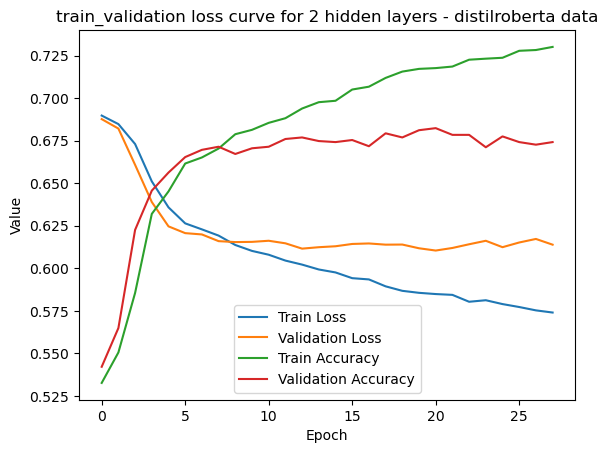

In [232]:
train_val(train_loss, val_loss, train_acc, val_acc, title='train_validation loss curve for 2 hidden layers - distilroberta data')

* This model overfitted to the training data

### DistilRoberta - Hyperparameter tuning 3 hidden layer

In [247]:
net_3 = NeuralNetClassifier(
    module=MLP,
    module__input_size=X_train_distilroberta_train_tensor.shape[1],
    module__hidlayers=3,  
    module__hidden_sizes=[52, 25, 10],
    module__output_size=2,
    module__activation=nn.LeakyReLU(),
    batch_size=128,
    max_epochs=60,
    criterion=torch.nn.CrossEntropyLoss(),
    optimizer=torch.optim.SGD,
    optimizer__lr=0.001,
    module__dropout=0.0,
    optimizer__momentum=0.9,
    callbacks=[
        callbacks.EpochScoring(scoring='accuracy', name='train_acc', on_train=True),
        callbacks.EarlyStopping(monitor='valid_loss',patience = 30, threshold = 0.01)
    ]
)


param_grid3 = {
    'module__hidden_sizes': [[52, 25, 10],[60,30,20], [65,50,30], [40,20,10], [100,70,40]],
    'optimizer__lr':[0.001, 0.01, 0.1, 1],
    'optimizer__momentum':[0, 0.5, 0.9],
    'module__dropout': [0.0, 0.2, 0.5]
    
}

grid_3 = GridSearchCV(estimator=net_3, param_grid=param_grid3, n_jobs=-1, cv=5)

In [248]:
grid_result_distilroberta = grid_3.fit(X_train_distilroberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())

There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/hugg

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4579        0.6946       0.4577        0.6946  0.1189
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4580        0.6979       0.4577        0.6978  0.1190
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5420        0.6923       0.5423        0.6922  0.1397
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4580        0.6948       0.4577        0.6948  0.1453
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4845

In [249]:
grid_result_distilroberta.best_params_

{'module__dropout': 0.2,
 'module__hidden_sizes': [65, 50, 30],
 'optimizer__lr': 0.1,
 'optimizer__momentum': 0.9}

In [250]:
grid_result_distilroberta.best_score_

0.6721480582524272

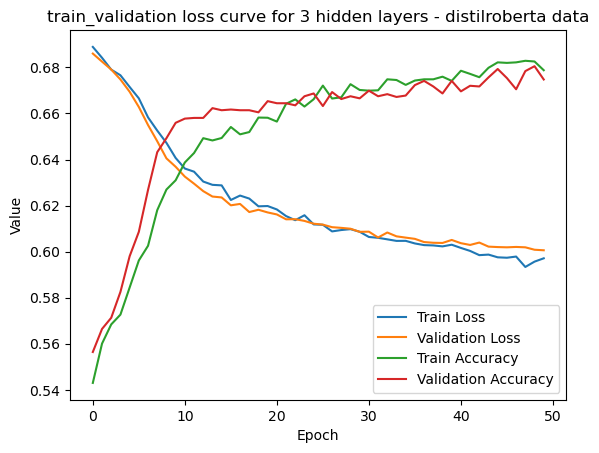

In [252]:
train_val(train_loss, val_loss, train_acc, val_acc, title='train_validation loss curve for 3 hidden layers - distilroberta data')

* Unlike the performance of the best parameter in 3 hidden layers and other hyperparameter tuning in Roberta, this gave a better result in distilroberta

### Distilroberta - 1 hidden layer

In [253]:
# Define the MLP module with 1 hidden layer
class MLP1(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, activation, dropout):
        super(MLP1, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)  # First and only hidden layer
        self.activation = activation
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_size, output_size)  # Output layer

    def forward(self, x):
        x = self.activation(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Initialize the NeuralNetClassifier with 1 hidden layer
net_1_hidden_layer = NeuralNetClassifier(
    module=MLP1,
    module__input_size=X_train_distilroberta_train_tensor.shape[1],  
    module__hidden_size=50,  
    module__output_size=2,  
    module__activation=nn.LeakyReLU(),  
    module__dropout=0.5,  
    max_epochs=50,
    batch_size=128,
    criterion=torch.nn.CrossEntropyLoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.01,
    train_split=dataset.ValidSplit(cv=5, stratified=True),  
    optimizer__momentum=0.9,
    callbacks=[
        callbacks.EpochScoring(scoring='accuracy', name='train_acc', on_train=True),
        callbacks.EarlyStopping(monitor='valid_loss',patience = 30, threshold = 0.01)
    ]
)

# Fit the model
net_1_hidden_layer.fit(X_train_distilroberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())


  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5334        0.6916       0.5528        0.6864  0.1910
      2       0.5557        0.6854       0.5607        0.6829  0.1687
      3       0.5617        0.6814       0.5725        0.6799  0.1208
      4       0.5764        0.6773       0.5804        0.6761  0.1096
      5       0.5795        0.6731       0.5886        0.6720  0.1523
      6       0.5909        0.6677       0.6001        0.6664  0.1098
      7       0.5963        0.6647       0.6135        0.6607  0.1118
      8       0.6025        0.6581       0.6271        0.6532  0.1604
      9       0.6203        0.6526       0.6344        0.6470  0.1238
     10       0.6319        0.6442       0.6402        0.6400  0.1067
     11       0.6358        0.6391       0.6481        0.6354  0.1324
     12       0.6430        0.6355       0.6453        0.6314  0.1105
     13       0.6435

<class 'skorch.classifier.NeuralNetClassifier'>[initialized](
  module_=MLP1(
    (fc1): Linear(in_features=70, out_features=50, bias=True)
    (activation): LeakyReLU(negative_slope=0.01)
    (dropout): Dropout(p=0.5, inplace=False)
    (fc2): Linear(in_features=50, out_features=2, bias=True)
  ),
)

In [254]:
train_loss = net_1_hidden_layer.history[:, 'train_loss']
train_acc = net_1_hidden_layer.history[:, 'train_acc']
val_loss = net_1_hidden_layer.history[:, 'valid_loss']
val_acc = net_1_hidden_layer.history[:, 'valid_acc']

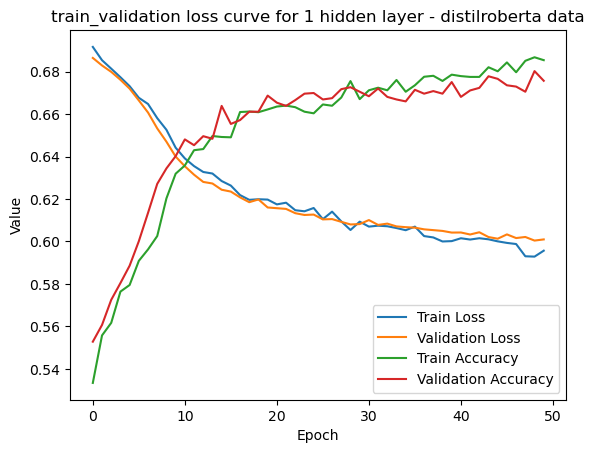

In [255]:
train_val(train_loss, val_loss, train_acc, val_acc, title='train_validation loss curve for 1 hidden layer - distilroberta data')

#### Hyperparameter Tuning of Hidden Layer 1

In [256]:
param_grid1 = {
    'module__hidden_size': [52,60,40,25],  
    'optimizer__lr': [0.001, 0.01, 0.1, 1],  
    'optimizer__momentum': [0, 0.5, 0.9],
    'module__dropout': [0.0, 0.2, 0.5]
}

grid1 = GridSearchCV(estimator=net_1_hidden_layer, param_grid=param_grid1, n_jobs=-1, cv=5)

In [257]:
grid_result_distilroberta = grid1.fit(X_train_distilroberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())

There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/hugg

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4886        0.6975       0.4968        0.6977  0.1504
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4588        0.7064       0.4589        0.7043  0.1538
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5366        0.6920       0.5339        0.6921  0.1427
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4671        0.7002       0.4725        0.7002  0.1491
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5388

In [258]:
grid_result_distilroberta.best_params_

{'module__dropout': 0.5,
 'module__hidden_size': 40,
 'optimizer__lr': 0.1,
 'optimizer__momentum': 0.9}

Re-initializing module because the following parameters were re-set: module__dropout, module__hidden_size.
Re-initializing criterion.
Re-initializing optimizer.
Re-initializing module because the following parameters were re-set: activation, dropout, hidden_size, input_size, output_size.
Re-initializing criterion.
Re-initializing optimizer.
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5529        0.6867       0.5907        0.6723  0.2337
      2       0.5972        0.6665       0.6417        0.6416  0.1300
      3       0.6181        0.6527       0.6462        0.6304  0.1620
      4       0.6262        0.6467       0.6520        0.6288  0.1498
      5       0.6365        0.6382       0.6547        0.6262  0.1264
      6       0.6366        0.6353       0.6623        0.6190  0.1224
      7       0.6452        0.6284       0.6629        0.6157  0.1369
      8       0.6497       

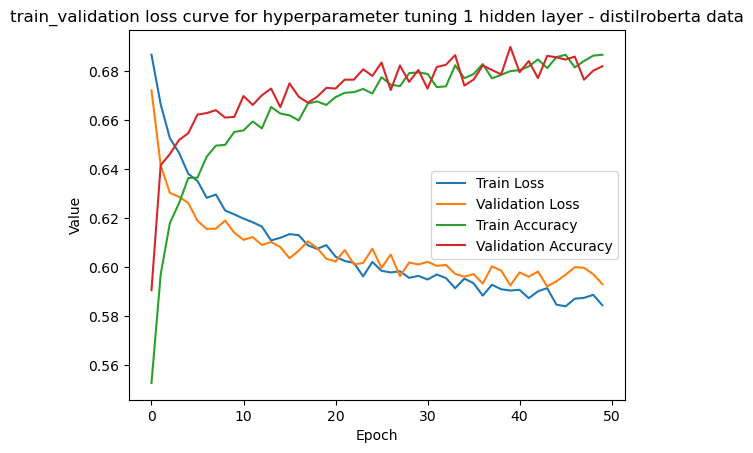

In [264]:
# Update the parameters of the neural network with the best found parameters
net_param = net_1_hidden_layer.set_params(**grid_result_roberta.best_params_)

# Fit the model with the best parameters using the training data
net_param.fit(X_train_distilroberta_train_tensor.numpy(), y_train_tensor.numpy().ravel())

train_loss = net_param.history[:, 'train_loss']
train_acc = net_param.history[:, 'train_acc']
val_loss = net_param.history[:, 'valid_loss']
val_acc = net_param.history[:, 'valid_acc']

train_val(train_loss, val_loss, train_acc, val_acc, title='train_validation loss curve for hyperparameter tuning 1 hidden layer - distilroberta data')

* As expected due to similarities between scores of roberta and distilbert, the hyperparameter tuning here didn't give a better result than the manual tuned option

**The final model selected is the 50 neurons, 1 hidden layer, 0.001 lr and 0.9 momentum for distilroberta**

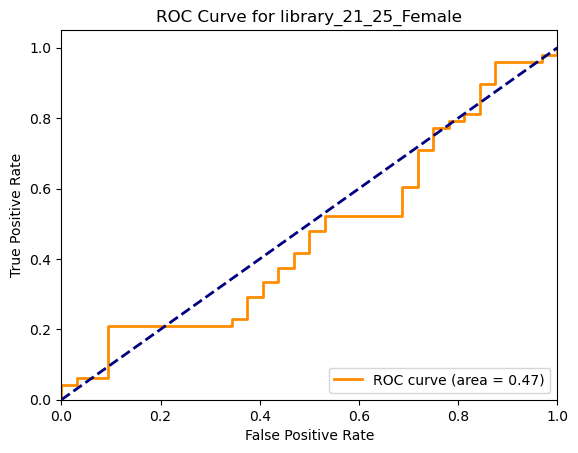

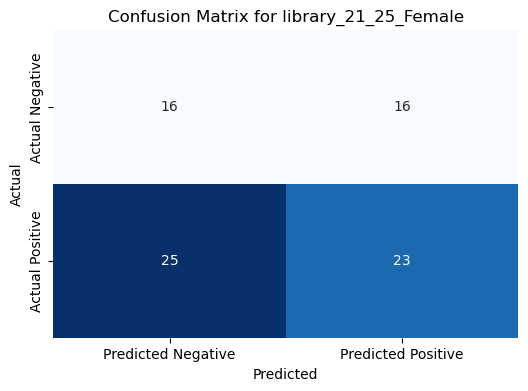

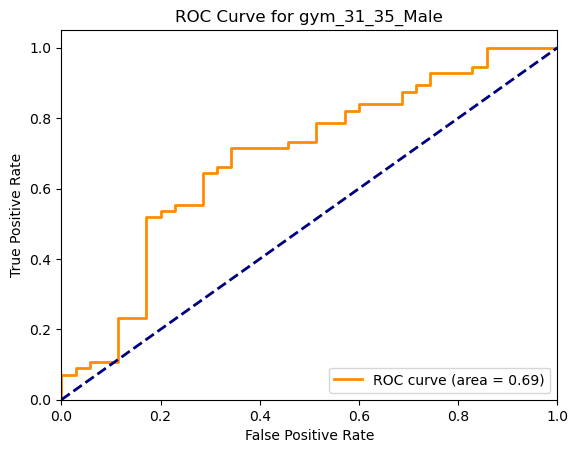

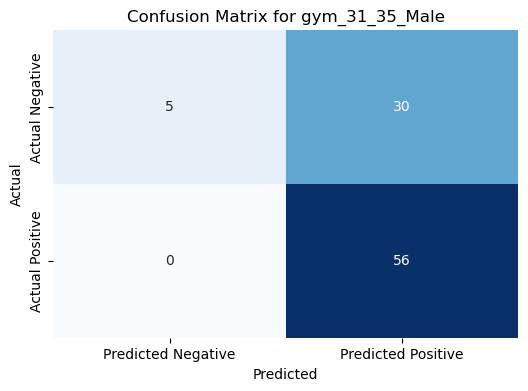

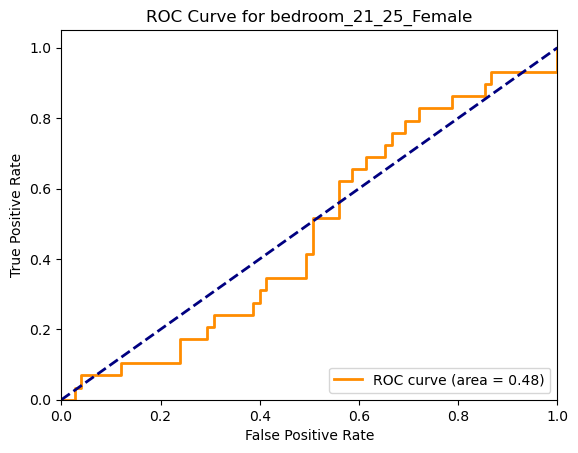

...

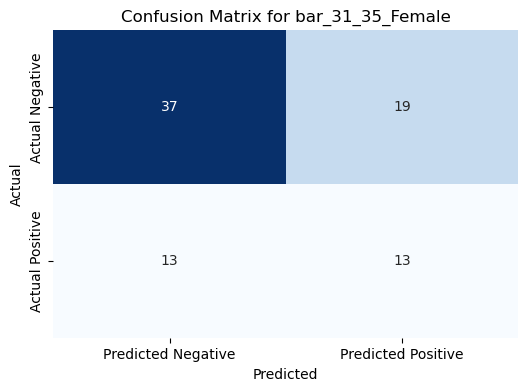

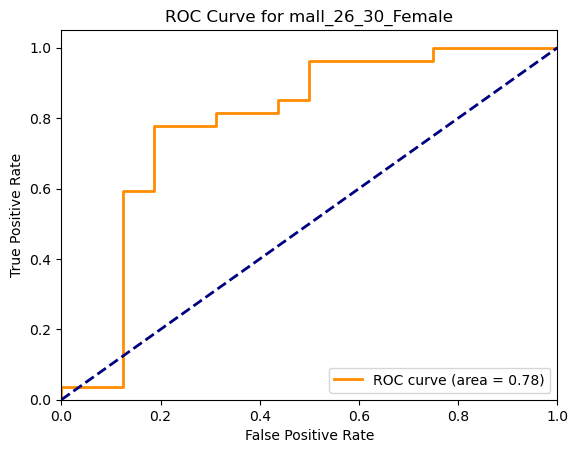

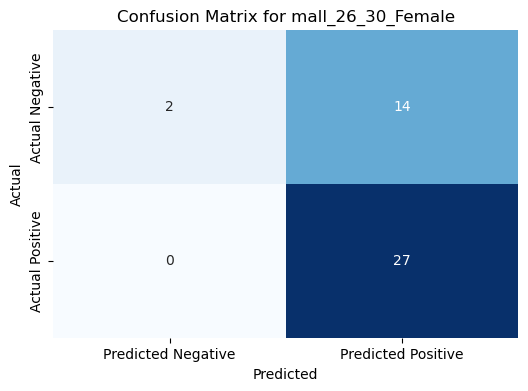

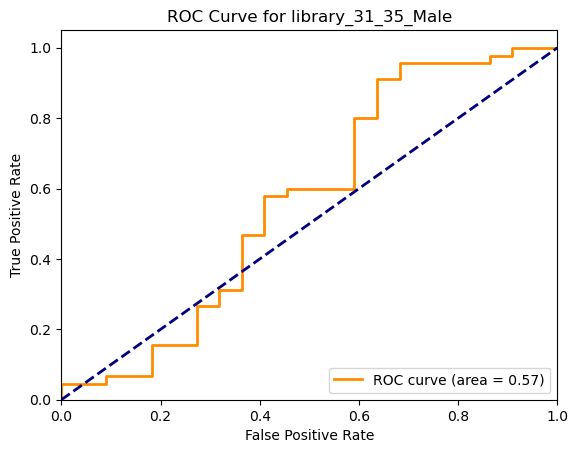

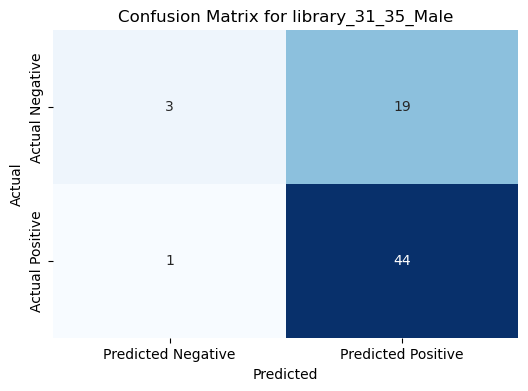

In [268]:
# evaluate target group on validation set
metrics_distilroberta, results_distilroberta = evaluate_model_by_group(X_val_distilroberta_tensor, y_val, target_group_val_split, net_1_hidden_layer, k=20)


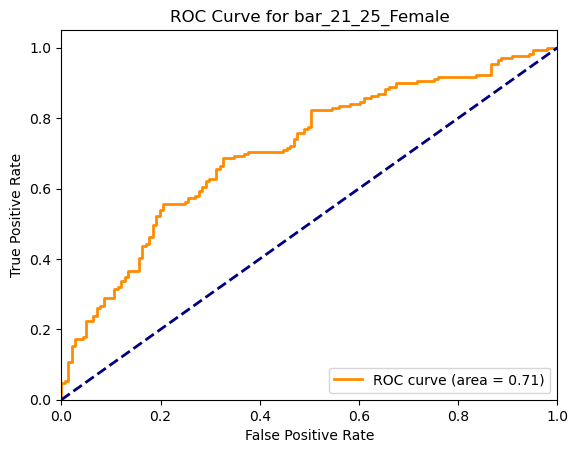

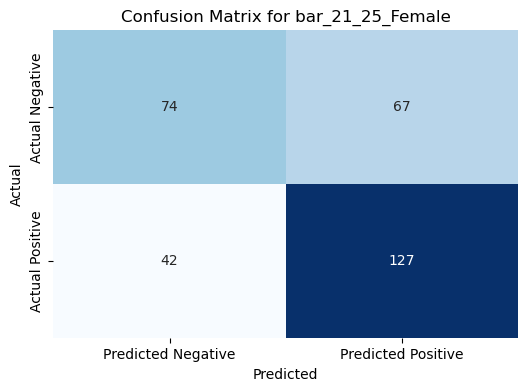

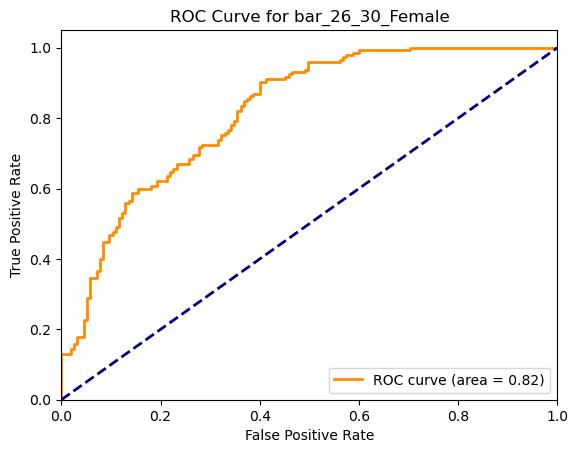

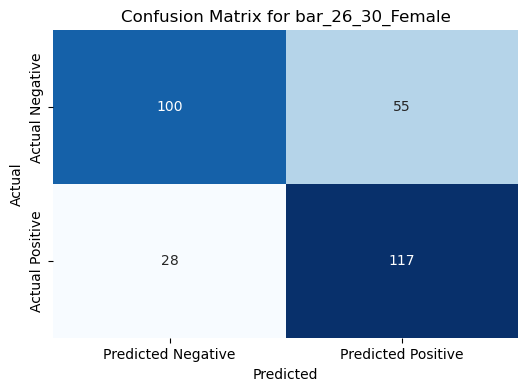

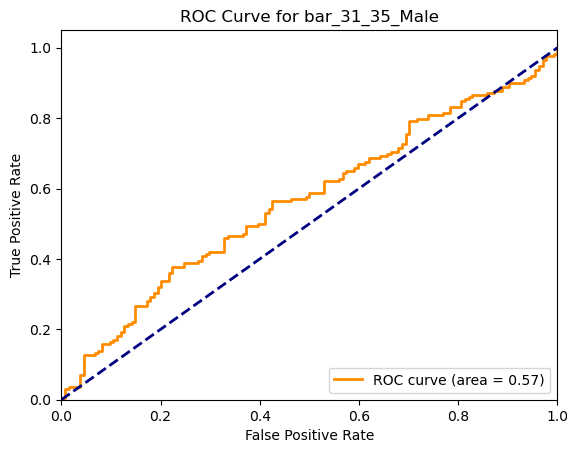

...

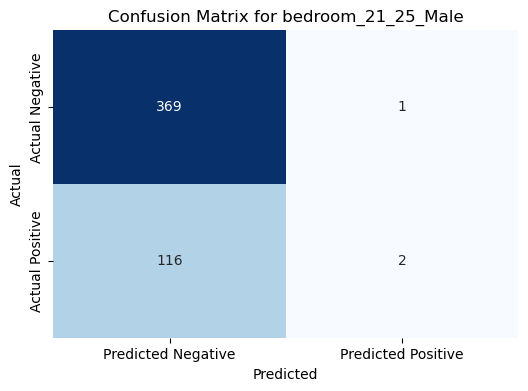

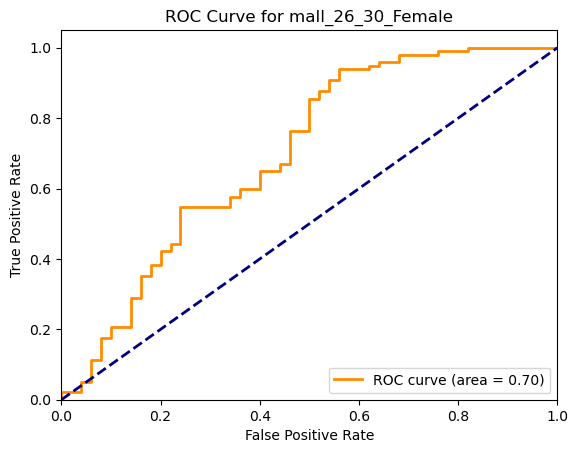

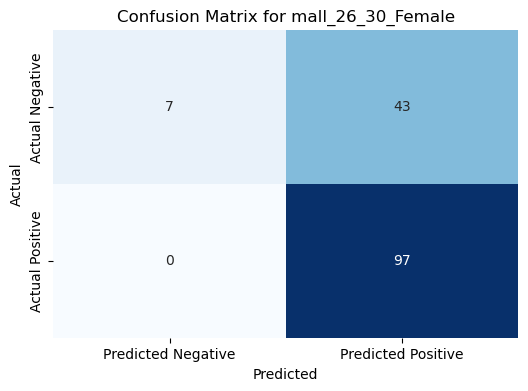

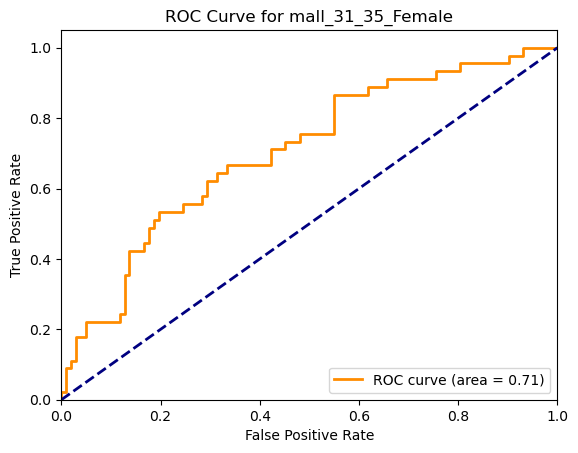

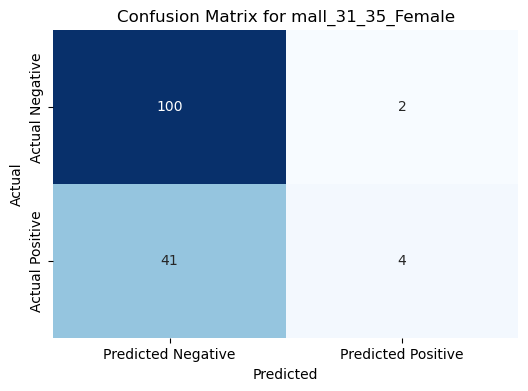

In [269]:
# evaluate target group on train set to check overfitting
metrics_distilroberta_t, results_distilroberta_t = evaluate_model_by_group(X_train_distilroberta_train_tensor, y_train_train, target_group_train_split, net_1_hidden_layer, k=20)

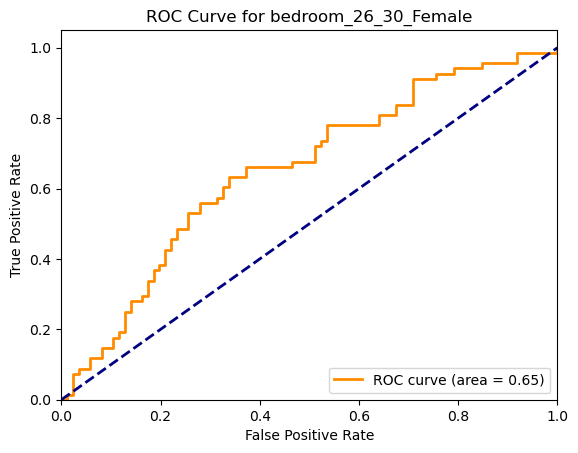

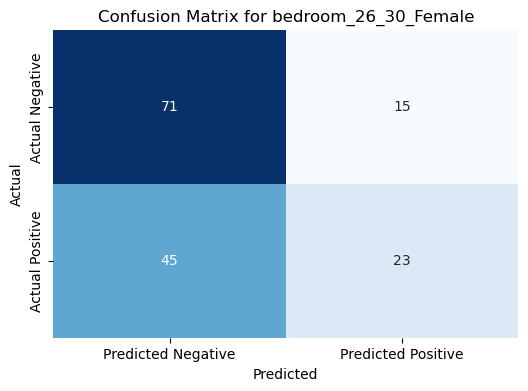

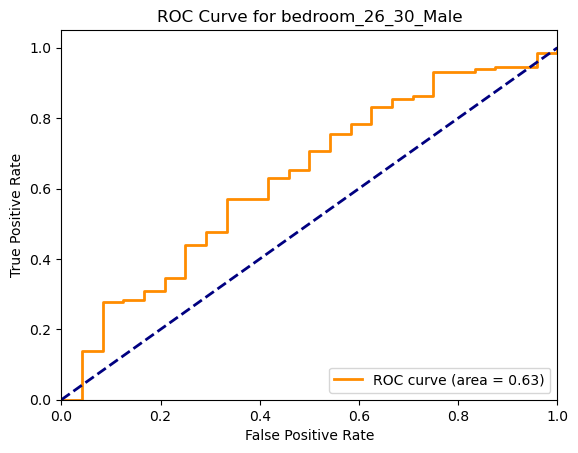

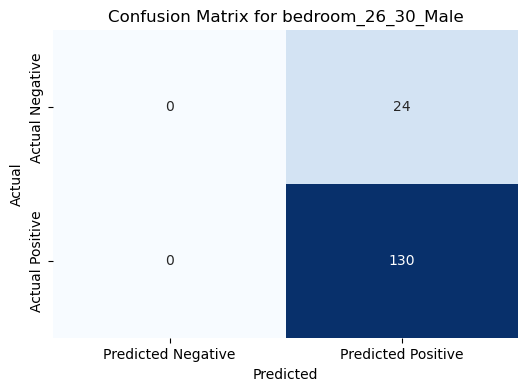

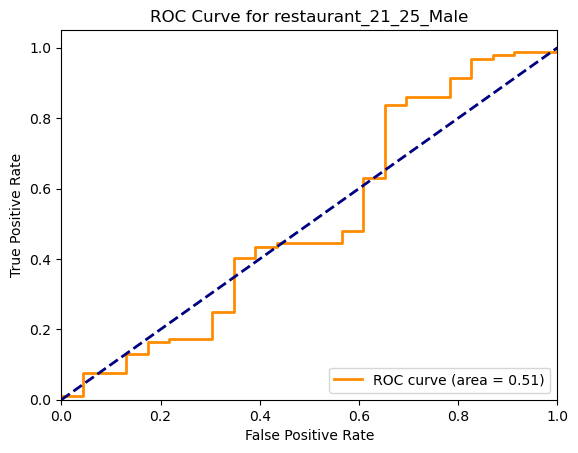

...

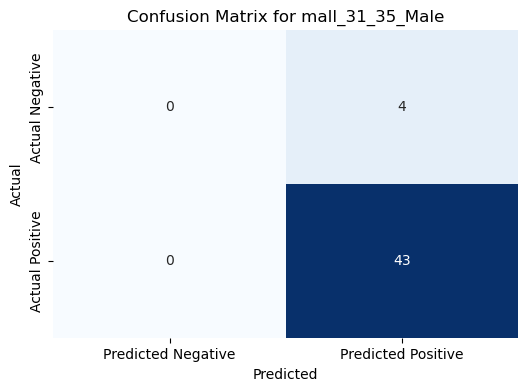

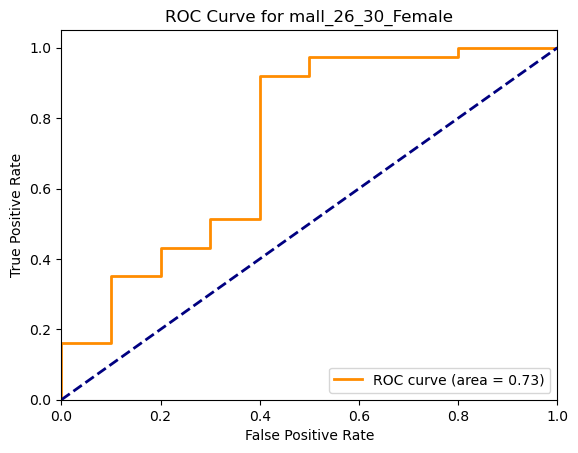

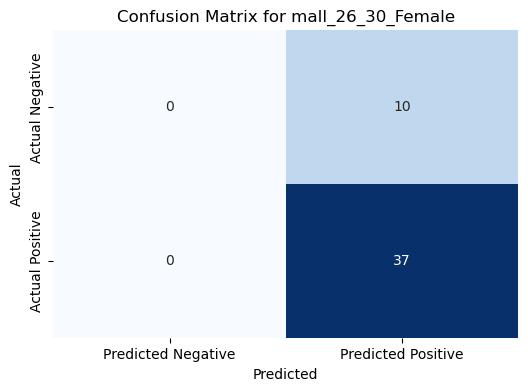

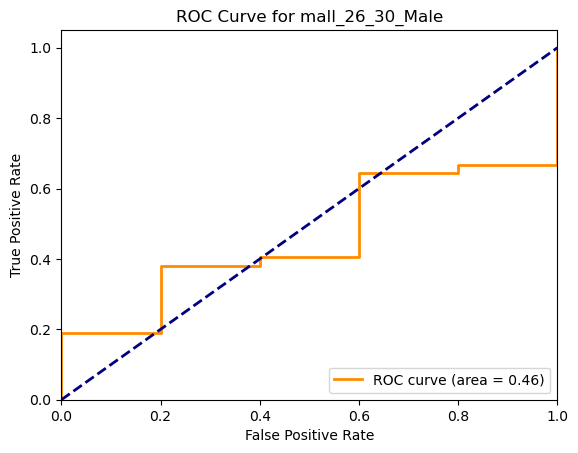

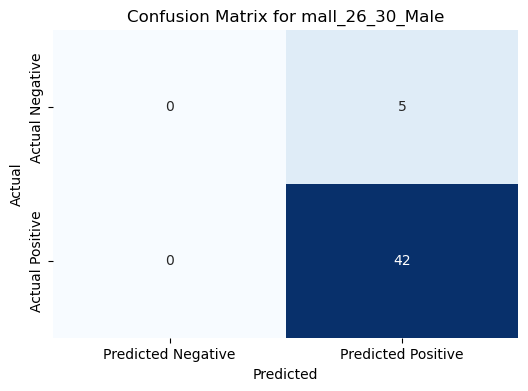

In [270]:
# Evaluate on the test set
X_test_distilroberta_tensor = torch.from_numpy(X_test_distilroberta.to_numpy()).type(torch.FloatTensor)


metrics_distilroberta_test, results_distilroberta_test = evaluate_model_by_group(X_test_distilroberta_tensor, y_test, target_group_test, net_1_hidden_layer, k=20)


In [319]:
# Save result of performance on target group
metrics_distilroberta_test.to_csv('metrics_distilroberta_test_mlp.csv', index=False)

## Distilroberta_mitch

### Apply the baseline model (it has 2 hidden layers)

In [272]:
net, val_losses, val_accuracy, train_loss, total_time = mlp_baseline_model(initialize_mlp,
                                                                           X_train_distilroberta_mitch_train_tensor,
                                                                           y_train_tensor)


  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4584        0.6944       0.4590        0.6945  0.2298
      2       0.4586        0.6944       0.4581        0.6944  0.1435
      3       0.4587        0.6943       0.4590        0.6944  0.1638
      4       0.4589        0.6943       0.4587        0.6944  0.1188
      5       0.4589        0.6942       0.4603        0.6943  0.1186
      6       0.4593        0.6942       0.4618        0.6943  0.1235
      7       0.4592        0.6941       0.4621        0.6942  0.1928
      8       0.4600        0.6941       0.4627        0.6942  0.1078
      9       0.4605        0.6941       0.4627        0.6941  0.1321
     10       0.4613        0.6940       0.4633        0.6941  0.1532
     11       0.4616        0.6940       0.4609        0.6941  0.1472
     12       0.4627        0.6939       0.4636        0.6940  0.1129
     13       0.4639

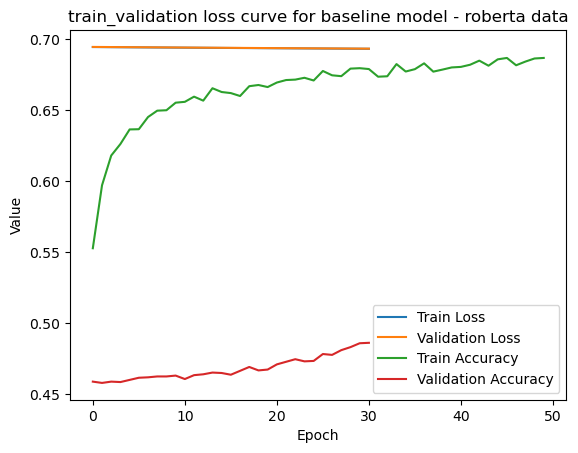

In [273]:
train_val(train_loss, val_losses, train_acc, val_accuracy, title='train_validation loss curve for baseline model - roberta data')

* Baseline model perfomed poorly on distilroberta mitch. Please ignore title on chart. The correct title is **train_validation loss curve for baseline model - distilroberta mitch) 

### hyperparameter tuning with hidden layer 2
For fair comparison purpose this was also done to distilrobeberta mitch, despite its overfitting tendency as seen in the other two dataset

In [275]:
from skorch import NeuralNetClassifier, callbacks, dataset
net_model2 = NeuralNetClassifier(
    module=MLP,  
    module__input_size=X_train_distilroberta_mitch_train_tensor.shape[1],  
    module__hidlayers=2,  
    module__hidden_sizes=[52, 25],  
    module__output_size=2,  
    module__activation=nn.LeakyReLU(),  
    batch_size=128,
    max_epochs=60,
    criterion=nn.CrossEntropyLoss,  
    optimizer=torch.optim.SGD,  
    optimizer__lr=0.01,  
    module__dropout=0.2,  
    optimizer__momentum=0.9,  
    train_split=dataset.ValidSplit(cv=5, stratified=True),
    callbacks=[
        callbacks.EpochScoring(scoring='accuracy', name='train_acc', on_train=True),
        callbacks.EarlyStopping(monitor='valid_loss',patience = 20, threshold = 0.01)
    ]
)

param_grid2 = {
    'module__hidden_sizes': [[52, 25], [60,30], [40,20], [100, 50]],  
    'optimizer__lr': [0.001, 0.01, 0.1, 1],  
    'optimizer__momentum': [0, 0.5, 0.9],
    'module__dropout': [0.0, 0.2, 0.5]
}

grid2 = GridSearchCV(estimator=net_model2, param_grid=param_grid2, n_jobs=-1, cv=5)

In [276]:
grid_result_distilroberta_mitch2 = grid2.fit(X_train_distilroberta_mitch_train_tensor.numpy(), y_train_tensor.numpy().ravel())


There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/hugg

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5420        0.6911       0.5423        0.6910  0.2479
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4579        0.6972       0.4577        0.6973  0.2151
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5420        0.6910       0.5423        0.6911  0.2199
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5421        0.6919       0.5423        0.6919  0.2670
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4580

In [277]:
grid_result_distilroberta_mitch2.best_params_

{'module__dropout': 0.5,
 'module__hidden_sizes': [52, 25],
 'optimizer__lr': 0.1,
 'optimizer__momentum': 0.9}

In [278]:
grid_result_distilroberta_mitch2.best_score_

0.673118932038835

In [279]:
# Update the parameters of the neural network with the best found parameters
net_model2.set_params(**best_params)

# Fit the model with the best parameters using your training data
net_model2.fit(X_train_distilroberta_mitch_train_tensor.numpy(), y_train_tensor.numpy().ravel())

# If you want to evaluate it after fitting
train_loss = net_model2.history[:, 'train_loss']
train_acc = net_model2.history[:, 'train_acc']
val_loss = net_model2.history[:, 'valid_loss']
val_acc = net_model2.history[:, 'valid_acc']

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5322        0.6904       0.5422        0.6886  0.2452
      2       0.5460        0.6862       0.5658        0.6834  0.2262
      3       0.5816        0.6767       0.6038        0.6679  0.2072
      4       0.6230        0.6534       0.6396        0.6386  0.1858
      5       0.6402        0.6397       0.6599        0.6270  0.2106
      6       0.6547        0.6298       0.6620        0.6232  0.2306
      7       0.6606        0.6264       0.6660        0.6206  0.2910
      8       0.6722        0.6193       0.6617        0.6204  0.1901
      9       0.6735        0.6170       0.6654        0.6186  0.1831
     10       0.6783        0.6138       0.6678        0.6210  0.1901
     11       0.6815        0.6110       0.6702        0.6173  0.2043
     12       0.6862        0.6064       0.6705        0.6173  0.3089
     13       0.6898

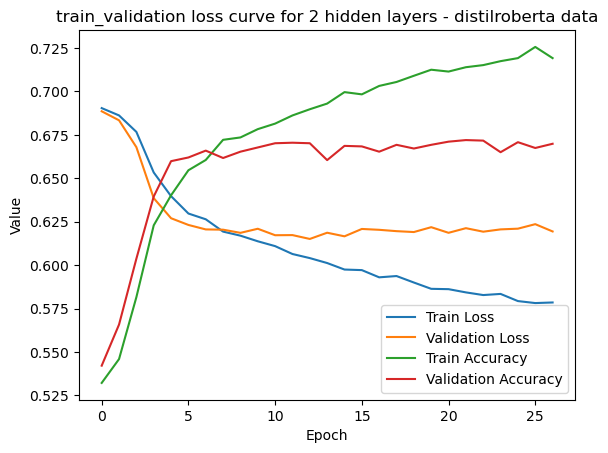

In [280]:
train_val(train_loss, val_loss, train_acc, val_acc, title='train_validation loss curve for 2 hidden layers - distilroberta data')

* Model overfitted

### hyperparameter tuning hidden layer 3

In [284]:
net_3 = NeuralNetClassifier(
    module=MLP,
    module__input_size=X_train_distilroberta_mitch_train_tensor.shape[1],
    module__hidlayers=3,  
    module__hidden_sizes=[52, 25, 10],
    module__output_size=2,
    module__activation=nn.LeakyReLU(),
    batch_size=128,
    max_epochs=60,
    criterion=torch.nn.CrossEntropyLoss(),
    optimizer=torch.optim.SGD,
    optimizer__lr=0.001,
    module__dropout=0.0,
    optimizer__momentum=0.9,
    callbacks=[
        callbacks.EpochScoring(scoring='accuracy', name='train_acc', on_train=True),
        callbacks.EarlyStopping(monitor='valid_loss',patience = 30, threshold = 0.01)
    ]
)


param_grid3 = {
    'module__hidden_sizes': [[52, 25, 10],[60,30,20], [65,50,30], [40,20,10], [100,70,40]],
    'optimizer__lr':[0.001, 0.01, 0.1, 1],
    'optimizer__momentum':[0, 0.5, 0.9],
    'module__dropout': [0.0, 0.2, 0.5]
    
}

grid_3 = GridSearchCV(estimator=net_3, param_grid=param_grid3, n_jobs=-1, cv=5)

In [291]:
grid_result_distilroberta_mitch3 = grid_3.fit(X_train_distilroberta_mitch_train_tensor.numpy(), y_train_tensor.numpy().ravel())

Stopping since valid_loss has not improved in the last 30 epochs.
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5420        0.6909       0.5423        0.6908  0.1634
Stopping since valid_loss has not improved in the last 30 epochs.
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4580        0.6940       0.4577        0.6941  0.1701
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5420        0.6909       0.5423        0.6908  0.1557
Stopping since valid_loss has not improved in the last 30 epochs.
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4610        0.69

In [292]:
grid_result_distilroberta_mitch3.best_params_

{'module__dropout': 0.2,
 'module__hidden_sizes': [52, 25, 10],
 'optimizer__lr': 1,
 'optimizer__momentum': 0.5}

In [293]:
grid_result_distilroberta_mitch3.best_score_

0.6725121359223301

In [294]:
# Update the parameters of the neural network with the best found parameters
net_3.set_params(**grid_result_distilroberta_mitch3.best_params_)

# Fit the model with the best parameters using the training data
net_3.fit(X_train_distilroberta_mitch_train_tensor.numpy(), y_train_tensor.numpy().ravel())

val_losses = net_3.history[:,'valid_loss']
val_accuracy = net_3.history[:,'valid_acc']
train_loss = net_3.history[:,'train_loss']
train_acc = net_3.history[:,'train_acc']
train_time = net_3.history[:,'dur']
#print('training time: ', sum(train_time))


  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5355        0.6898       0.5422        0.6884  0.1987
      2       0.5545        0.6847       0.5604        0.6818  0.1218
      3       0.6142        0.6621       0.6353        0.6466  0.1341
      4       0.6366        0.6435       0.6320        0.6480  0.1434
      5       0.6542        0.6328       0.6450        0.6412  0.1355
      6       0.6640        0.6258       0.6578        0.6331  0.1273
      7       0.6670        0.6228       0.6523        0.6359  0.1212
      8       0.6753        0.6180       0.6517        0.6351  0.1414
      9       0.6819        0.6135       0.6556        0.6318  0.1295
     10       0.6863        0.6093       0.6675        0.6275  0.1367
     11       0.6895        0.6073       0.6611        0.6276  0.1314
     12       0.6881        0.6056       0.6587        0.6266  0.1210
     13       0.6922

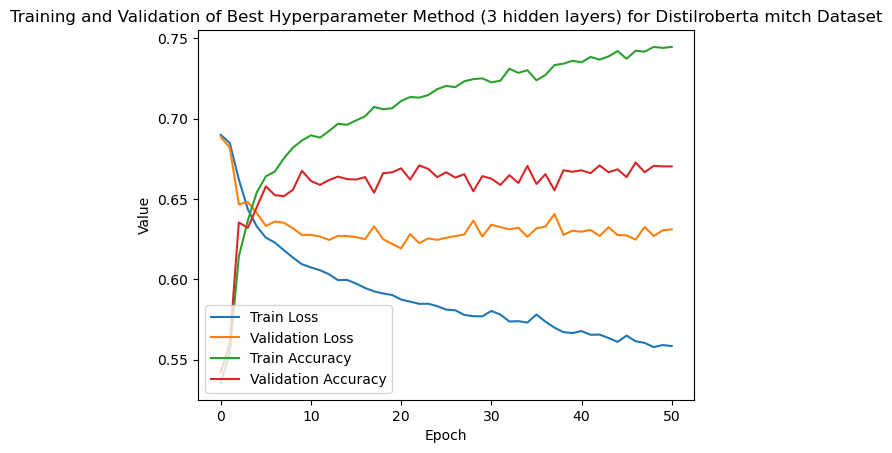

In [295]:
train_val(train_loss, val_losses, train_acc, val_accuracy, 'Training and Validation of Best Hyperparameter Method (3 hidden layers) for Distilroberta mitch Dataset')

* Overfiting occured as expected

### Experimenting on 1 hidden layer

In [300]:
# Define the MLP module with 1 hidden layer
class MLP1(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, activation, dropout):
        super(MLP1, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)  # First and only hidden layer
        self.activation = activation
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_size, output_size)  # Output layer

    def forward(self, x):
        x = self.activation(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Initialize the NeuralNetClassifier with 1 hidden layer
net_1_hidden_layer = NeuralNetClassifier(
    module=MLP1,
    module__input_size=X_train_distilroberta_mitch_train_tensor.shape[1],  
    module__hidden_size=50, 
    module__output_size=2,  
    module__activation=nn.LeakyReLU(),  
    module__dropout=0.5,  
    max_epochs=50,
    batch_size=128,
    criterion=torch.nn.CrossEntropyLoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.01,
    train_split=dataset.ValidSplit(cv=5, stratified=True),  
    optimizer__momentum=0.9,
    callbacks=[
        callbacks.EpochScoring(scoring='accuracy', name='train_acc', on_train=True),
        callbacks.EarlyStopping(monitor='valid_loss',patience = 30, threshold = 0.01)
    ]
)

# Fit the model
net_1_hidden_layer.fit(X_train_distilroberta_mitch_train_tensor.numpy(), y_train_tensor.numpy().ravel())


  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5430        0.6898       0.5473        0.6864  0.2466
      2       0.5611        0.6829       0.5555        0.6828  0.1062
      3       0.5701        0.6790       0.5640        0.6796  0.1155
      4       0.5730        0.6752       0.5768        0.6759  0.1117
      5       0.5870        0.6711       0.5944        0.6706  0.1142
      6       0.5978        0.6667       0.6044        0.6650  0.1159
      7       0.6060        0.6604       0.6186        0.6580  0.1101
      8       0.6141        0.6553       0.6292        0.6514  0.1136
      9       0.6217        0.6482       0.6377        0.6446  0.1609
     10       0.6355        0.6419       0.6471        0.6383  0.1984
     11       0.6352        0.6383       0.6517        0.6340  0.1338
     12       0.6458        0.6308       0.6544        0.6287  0.1463
     13       0.6469

<class 'skorch.classifier.NeuralNetClassifier'>[initialized](
  module_=MLP1(
    (fc1): Linear(in_features=69, out_features=50, bias=True)
    (activation): LeakyReLU(negative_slope=0.01)
    (dropout): Dropout(p=0.5, inplace=False)
    (fc2): Linear(in_features=50, out_features=2, bias=True)
  ),
)

In [301]:
val_losses = net_1_hidden_layer.history[:,'valid_loss']
val_accuracy = net_1_hidden_layer.history[:,'valid_acc']
train_loss = net_1_hidden_layer.history[:,'train_loss']
train_acc = net_1_hidden_layer.history[:,'train_acc']
train_time = net_1_hidden_layer.history[:,'dur']
print('training time: ', sum(train_time))

training time:  9.344561338424683


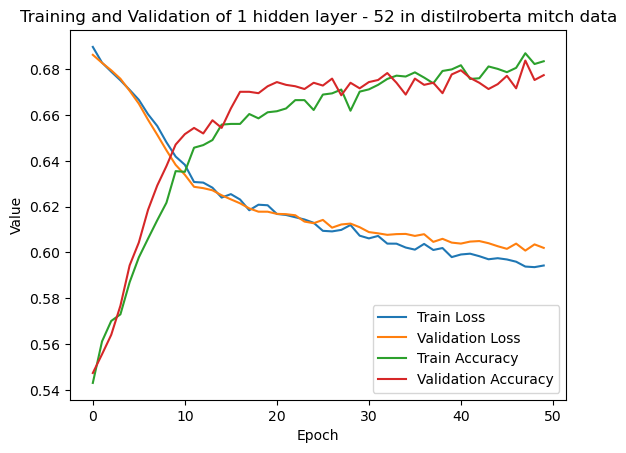

In [302]:
train_val(train_loss, val_losses, train_acc, val_accuracy, 'Training and Validation of 1 hidden layer - 52 in distilroberta mitch data')


* This model reduced overfitting

#### hyperparameter tuning of 1 hidden layer

In [303]:
net_1 = NeuralNetClassifier(
    module=MLP1,
    module__input_size=X_train_distilroberta_mitch_train_tensor.shape[1],  
    module__hidden_size=50, 
    module__output_size=2,  
    module__activation=nn.LeakyReLU(),  
    module__dropout=0.5,  
    max_epochs=50,
    batch_size=128,
    criterion=torch.nn.CrossEntropyLoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.01,
    train_split=dataset.ValidSplit(cv=5, stratified=True),  
    optimizer__momentum=0.9,
    callbacks=[
        callbacks.EpochScoring(scoring='accuracy', name='train_acc', on_train=True),
        callbacks.EarlyStopping(monitor='valid_loss',patience = 30, threshold = 0.01)
    ]
)



param_grid1 = {
    'module__hidden_size': [52,60,40,25],  
    'optimizer__lr': [0.001, 0.01, 0.1, 1],  
    'optimizer__momentum': [0, 0.5, 0.9],
    'module__dropout': [0.0, 0.2, 0.5]
}

grid1 = GridSearchCV(estimator=net_1, param_grid=param_grid1, n_jobs=-1, cv=5)

grid_result_distilroberta_mitch1 = grid1.fit(X_train_distilroberta_mitch_train_tensor.numpy(), y_train_tensor.numpy().ravel())

There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/huggingface/hub). You should set the environment variable TRANSFORMERS_CACHE to a writable directory.
There was a problem when trying to write in your cache folder (/Users/mac/.cache/hugg

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4656        0.7004       0.4744        0.6989  0.1510
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4593        0.6987       0.4710        0.6969  0.1342
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5143        0.6941       0.5241        0.6926  0.1521
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5117        0.6932       0.5119        0.6938  0.1384
  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.4720

In [304]:
grid_result_distilroberta_mitch1.best_params_

{'module__dropout': 0.5,
 'module__hidden_size': 52,
 'optimizer__lr': 0.1,
 'optimizer__momentum': 0.9}

  epoch    train_acc    train_loss    valid_acc    valid_loss     dur
-------  -----------  ------------  -----------  ------------  ------
      1       0.5644        0.6830       0.5989        0.6617  0.2379
      2       0.6029        0.6640       0.6420        0.6371  0.1023
      3       0.6149        0.6538       0.6390        0.6337  0.1237
      4       0.6274        0.6412       0.6517        0.6256  0.1087
      5       0.6404        0.6357       0.6599        0.6206  0.1098
      6       0.6438        0.6314       0.6587        0.6210  0.1248
      7       0.6474        0.6297       0.6596        0.6199  0.1578
      8       0.6514        0.6241       0.6726        0.6115  0.1565
      9       0.6567        0.6191       0.6717        0.6111  0.3249
     10       0.6584        0.6167       0.6635        0.6155  0.1060
     11       0.6594        0.6168       0.6623        0.6086  0.1220
     12       0.6633        0.6131       0.6650        0.6106  0.1790
     13       0.6667

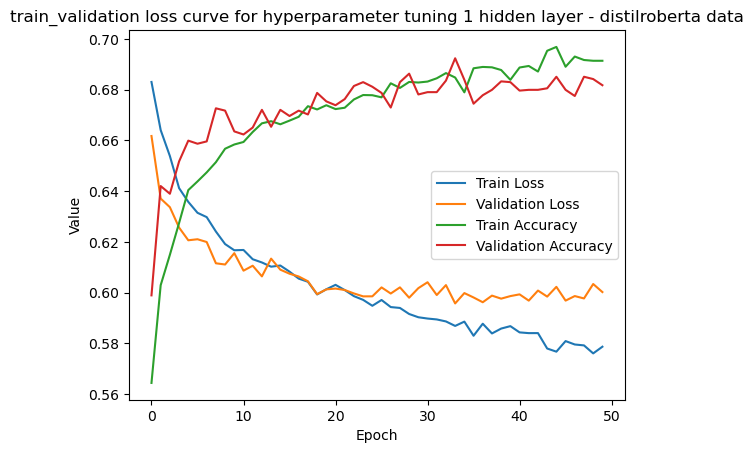

In [307]:
# Update the parameters of the neural network with the best found parameters
net_1.set_params(**grid_result_distilroberta_mitch1.best_params_)

# Fit the model with the best parameters using training data
net_1.fit(X_train_distilroberta_mitch_train_tensor.numpy(), y_train_tensor.numpy().ravel())

train_loss_hyper = net_1.history[:, 'train_loss']
train_acc_hyper = net_1.history[:, 'train_acc']
val_loss_hyper = net_1.history[:, 'valid_loss']
val_acc_hyper = net_1.history[:, 'valid_acc']

train_val(train_loss_hyper, val_loss_hyper, train_acc_hyper, val_acc_hyper, title='train_validation loss curve for hyperparameter tuning 1 hidden layer - distilroberta data')

**The final model for the distilroberta model was the model with 50 neurons, 1 hidden layer, 0.001 lr and 0.9 momentum**

## Validate on validation set

In [ ]:
net_1_hidden_layer

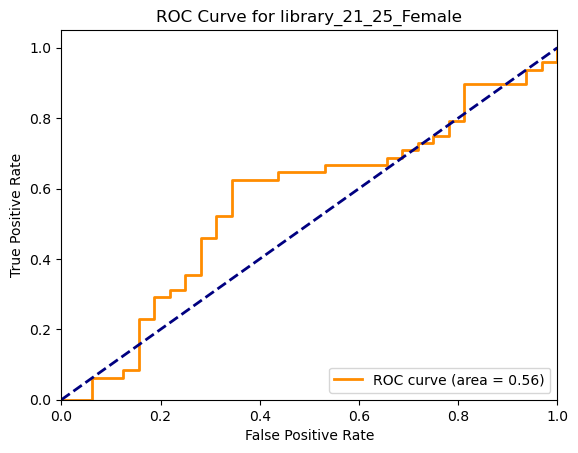

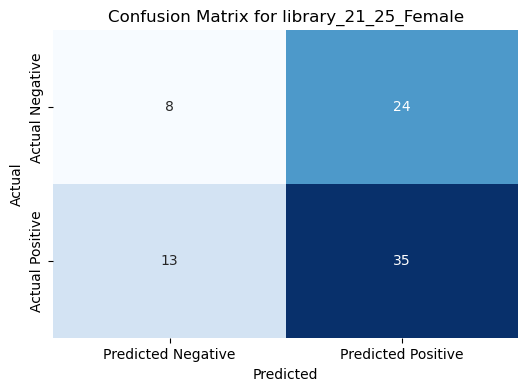

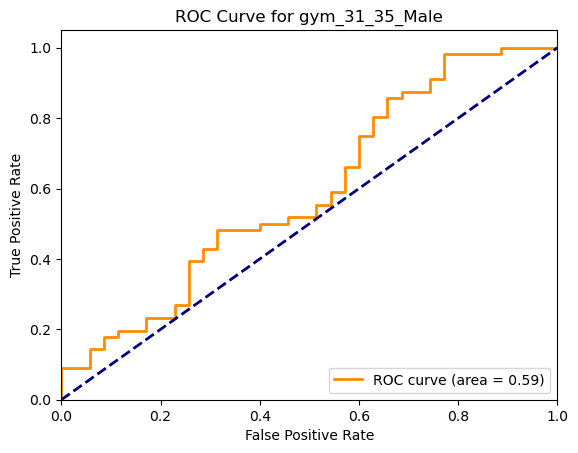

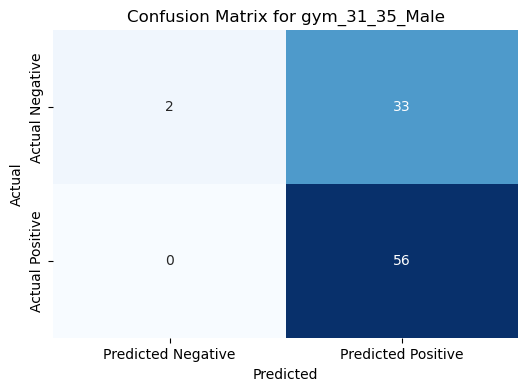

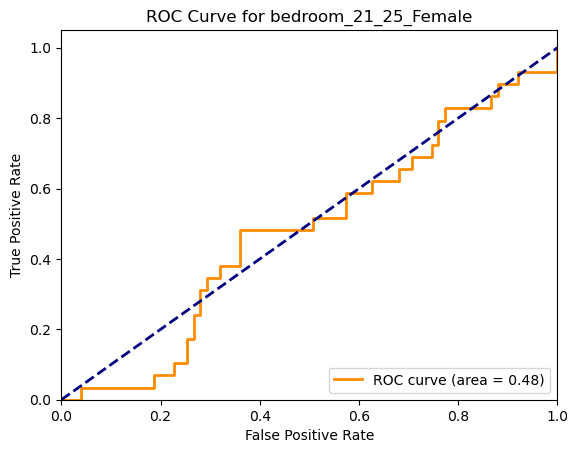

...

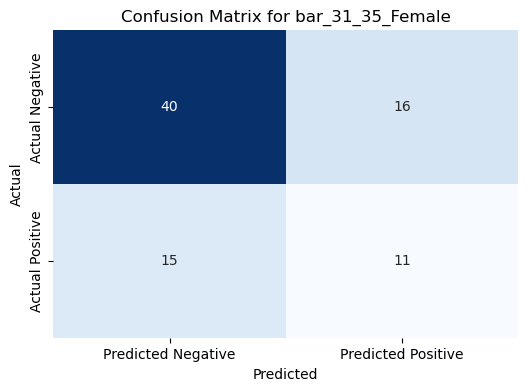

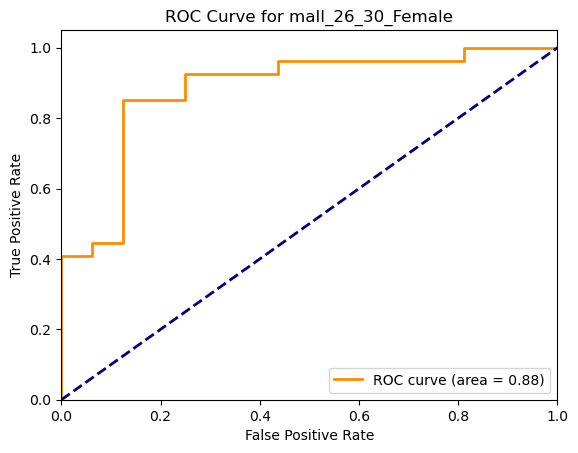

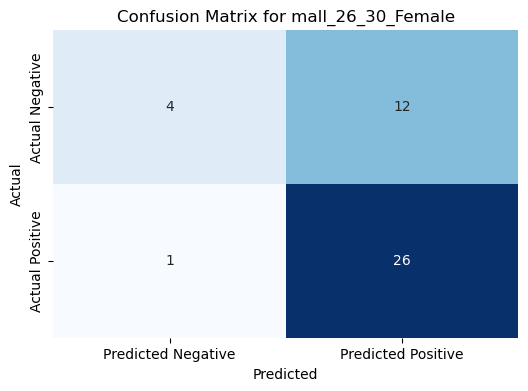

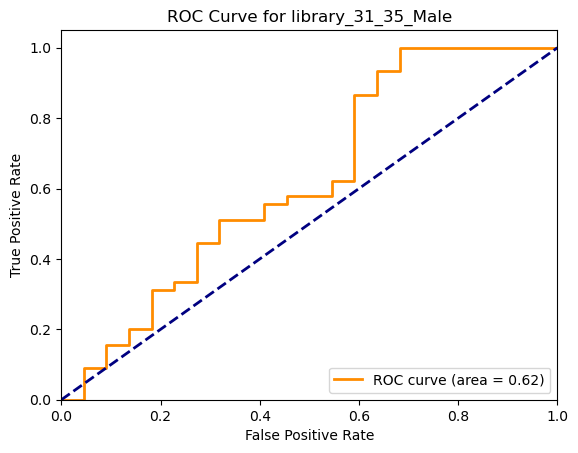

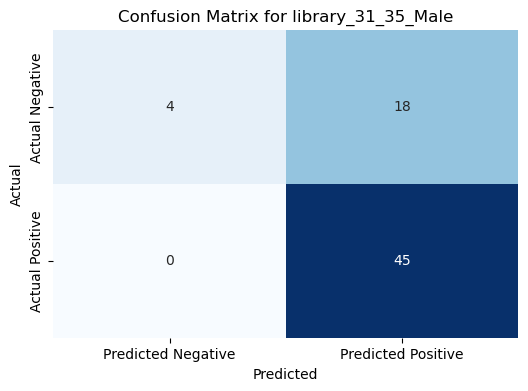

Stopping since valid_loss has not improved in the last 30 epochs.


In [308]:
metrics_distilroberta_mitch, results_distilroberta_mitch = evaluate_model_by_group(X_val_distilroberta_mitch_tensor, y_val, target_group_val_split, net_1_hidden_layer, k=20)


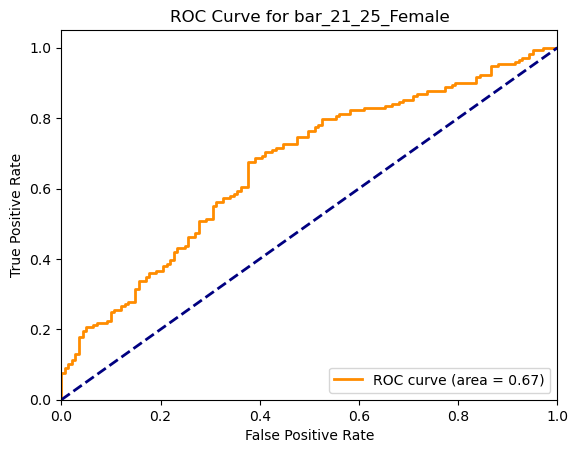

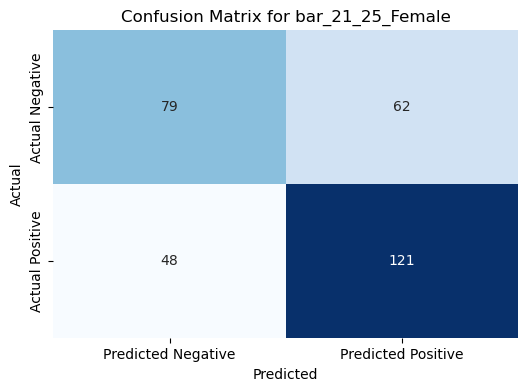

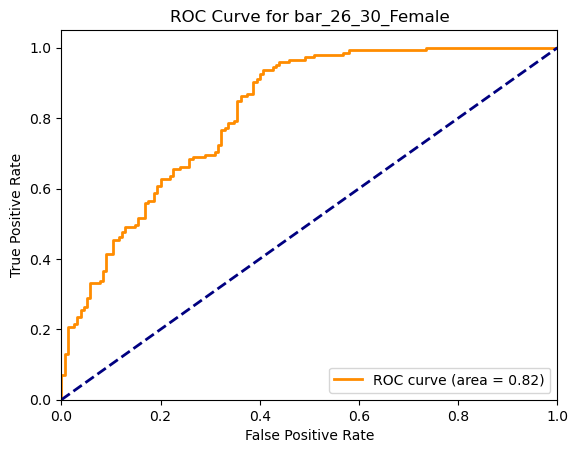

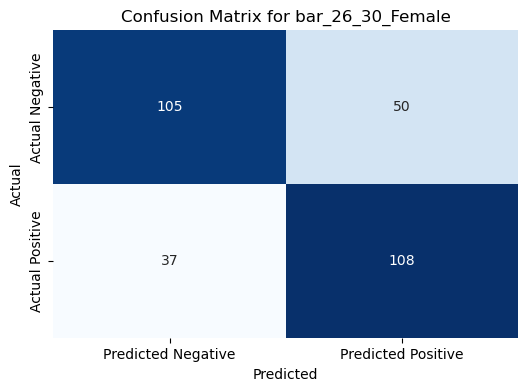

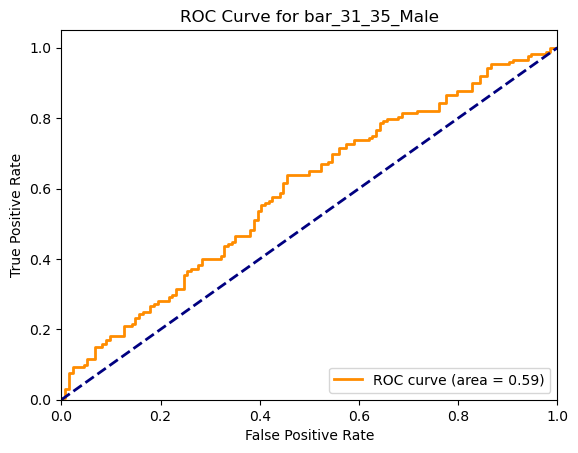

...

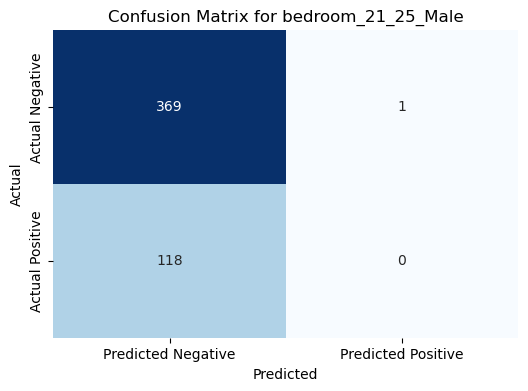

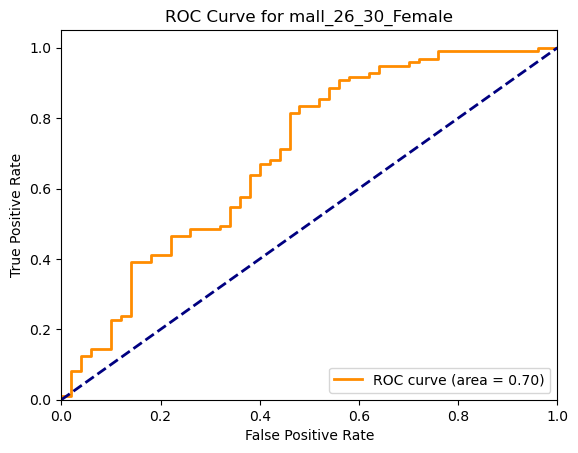

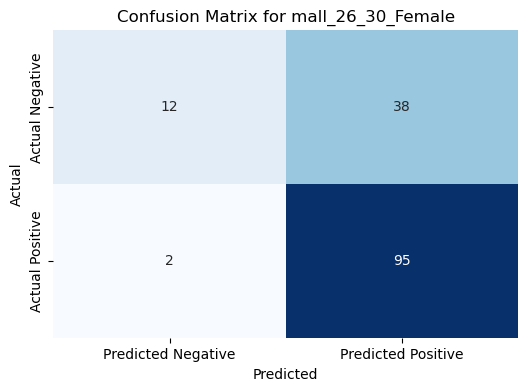

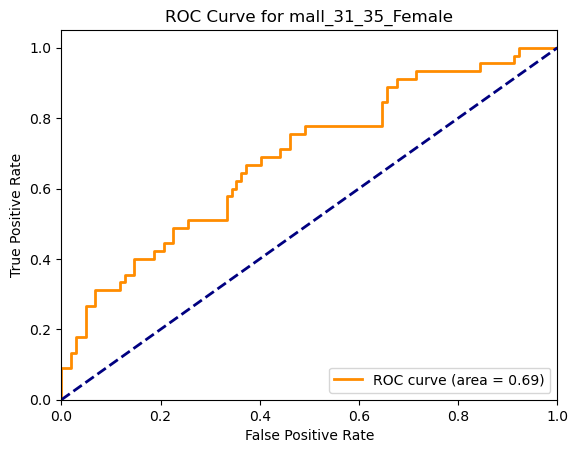

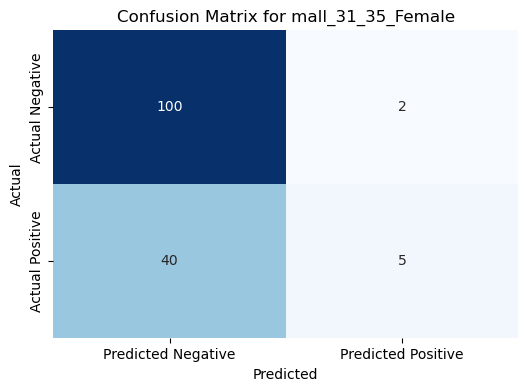

In [310]:
metrics_distilroberta_mitch_t, results_distilroberta_mitch_t = evaluate_model_by_group(X_train_distilroberta_mitch_train_tensor, y_train_train, target_group_train_split, net_1_hidden_layer, k=20)


##### Test and evaluate on test set

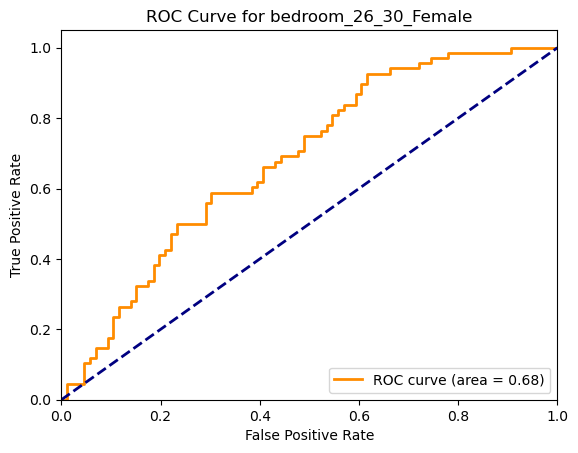

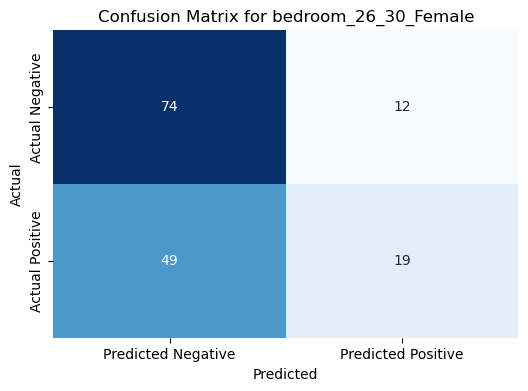

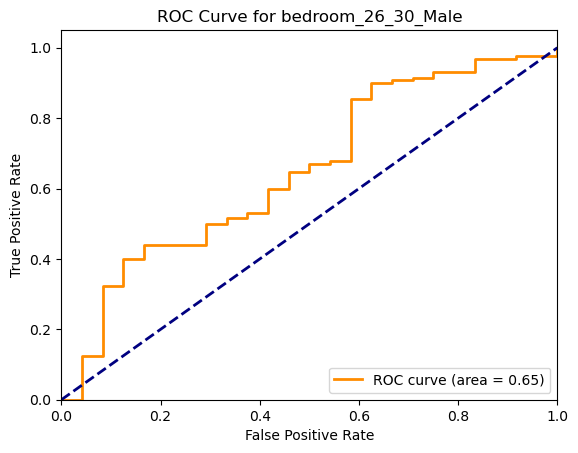

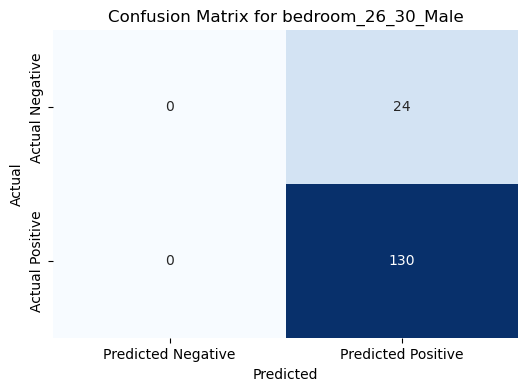

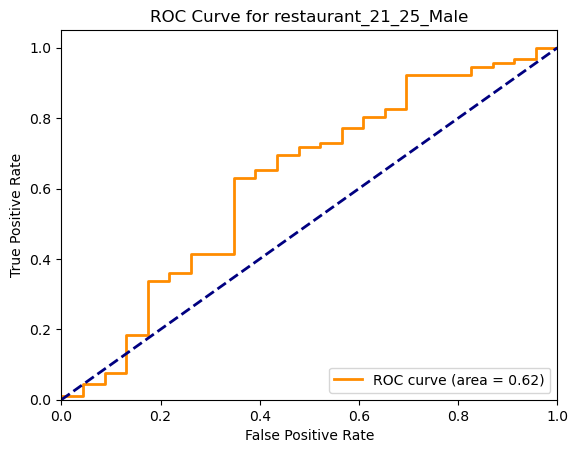

...

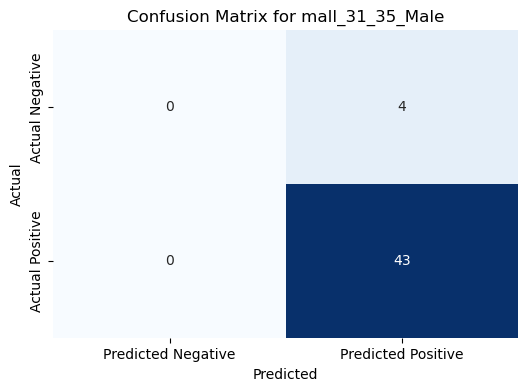

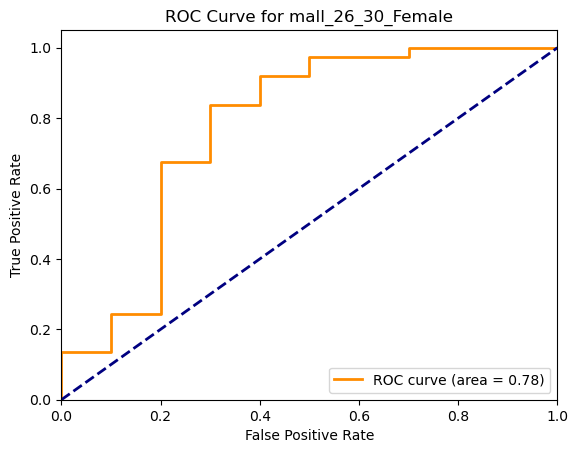

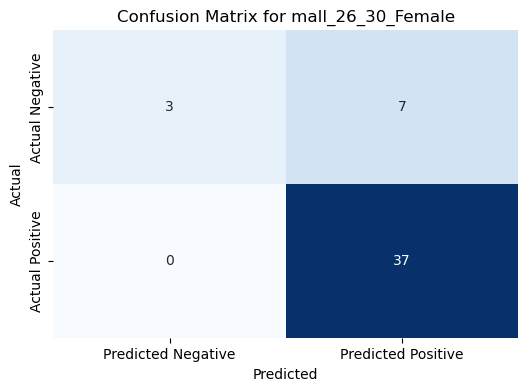

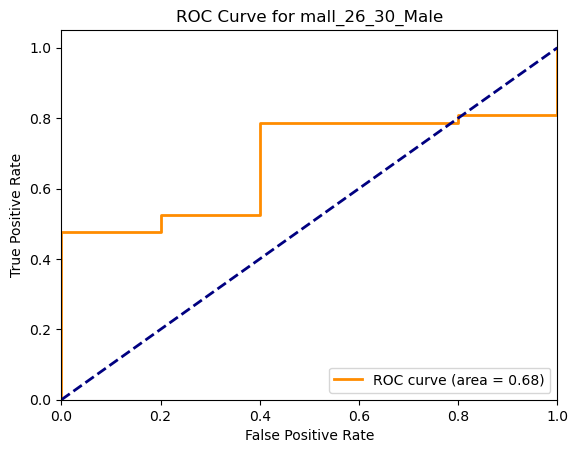

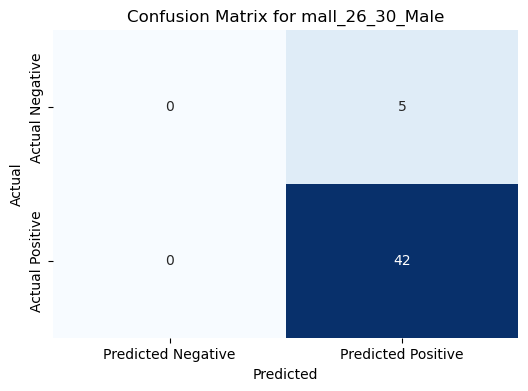

In [356]:
X_test_distilroberta_mitch_tensor = torch.from_numpy(X_test_distilroberta_mitch.to_numpy()).type(torch.FloatTensor)


metrics_distilroberta_mitch_test, results_distilroberta_mitch_test = evaluate_model_by_group(X_test_distilroberta_mitch_tensor, y_test, target_group_test, net_1_hidden_layer, k=20)


In [318]:
# Save result
metrics_distilroberta_mitch_test.to_csv('metrics_distilroberta_mitch_test_mlp.csv', index=False)

In [360]:
metrics_distilroberta_mitch_test

,target_group,precision_at_k,average_precision_at_k,ndcg_at_k,precision_score
0,bedroom_26_30_Female,0.600000,0.602326,0.562828,0.612903
1,bedroom_26_30_Male,0.900000,0.853066,0.824522,0.844156
2,restaurant_21_25_Male,0.850000,0.791319,0.818728,0.800000
3,mall_21_25_Female,0.800000,0.733647,0.715833,0.808511
4,trainbus_31_35_Male,0.850000,0.803060,0.836531,0.818182
5,bar_26_30_Male,0.800000,0.927245,0.851242,0.718750
6,library_26_30_Male,0.900000,0.925246,0.915347,0.733333
7,bedroom_31_35_Female,0.650000,0.804340,0.712083,0.470588
8,restaurant_31_35_Male,0.850000,0.967704,0.894527,0.763158
9,restaurant_21_25_Female,0.600000,0.748373,0.661468,0.544554


In [342]:
# Merge the three results for each dataset
merged_df_1_2 = pd.merge(metrics_roberta_test, metrics_distilroberta_test, on='target_group', how='inner')
final_merged_df = pd.merge(merged_df_1_2, metrics_distilroberta_mitch_test, on='target_group', how='inner')
sorted_metrics = final_merged_df.sort_values(by='target_group', ascending=True)

In [344]:
# Save the sorted DataFrame to an Excel file
sorted_metrics.to_excel('test_result.xlsx', index=False)